# EMG hand-gesture classification

Goal: predict which of 6 hand gestures (rest, fist, wrist flexion, wrist extension, radial deviation, ulnar deviation) a person makes,
from the 8 EMG channels of a MYO bracelet, **for a person whose data the model has never seen**.

## Pipeline overview

| Step | Section | What we do | Why |
|---|---|---|---|
| Raw data | 1-5 | 4.2 million rows, 8 channels, 36 subjects, 2 series each; explore classes, sampling rate, signal values, gesture blocks | Understand the data before choosing anything |
| Preparation | 7 | Remove class 0 (unmarked) and class 7 (extended palm) | Class 0 is pauses and transitions; class 7 was done by only 2 subjects |
| Cleaning | 8 | Remove repeated rows (89%) | They are copies written by the recording software; the real sampling rate is about 105 Hz |
| Windowing | 9 | 20 samples (about 190 ms), 50% overlap, never across two gesture blocks | A single sample says almost nothing; the information is in the signal over a short period |
| Feature construction | 9 | 5 feature types x 8 channels = 40 features per window | Common EMG features in the time and frequency domain |
| Split by subject | 10, 14 | **29 development subjects** for all choices, **7 test subjects** locked away | Scores must show how well the model works for a new person; windows of one person must never be in training and validation at the same time |
| Feature selection | 11, 12, 14b | **MAV (8 features)** selected, using the development subjects only | MAV, RMS and WL carry the same information; extra features do not help, also not in cross-validation |
| Model selection | 13-16b | `Pipeline(StandardScaler + model)`, 5-fold `GroupKFold` by subject; logistic regression baseline, MLP, random search, learning curves, depth check | The scaler is fitted inside every fold (no leakage); all choices are based on many subjects, not one split |
| Final model | 17 | MLP with 2 hidden layers (64, 32), `alpha` = 0.041, learning rate 0.00023, batch size 64, 25 epochs, MAV features | Best cross-validated F1 (0.835 vs 0.811); chosen **before** the test subjects were used |
| Final evaluation | 18 | Train on all 29 development subjects, score **once** on the 7 test subjects | Unbiased estimate for new people: **F1 0.780** (logistic regression 0.802) |

Safeguards against over-optimistic scores:
- Every split is made **by subject** (`GroupKFold`, `groups = subject`), never by window.
- The scaler is part of the pipeline, so it is fitted on training subjects only.
- The test subjects were not used for any choice (features, window length, model, hyper-parameters, number of epochs) and were scored once.

**Workflow figure for the report (to be made separately, e.g. in Canva).** One box per step, from top to bottom, connected by arrows.
Each box has the step name (with the section number) on the first line and one short line of detail below it:

1. **Raw data** - 4.2 million rows: 8 EMG channels, 36 subjects, 2 series each
2. **Preparation (sections 1-7)** - remove class 0 (unmarked) and class 7 (2 subjects only)
3. **Cleaning (section 8)** - remove repeated rows (89%): real sampling rate about 105 Hz
4. **Windowing (section 9)** - 20 samples (about 190 ms), 50% overlap, within one gesture block
5. **Feature construction (section 9)** - 5 feature types x 8 channels = 40 features per window
6. **Split by subject (sections 10, 14)** - 29 development subjects | 7 test subjects locked away
7. **Feature selection on development subjects only (sections 11, 12, 14b)** - MAV, RMS, WL nearly identical; MAV (8 features) selected
8. **Model selection on development subjects (sections 13-16b)** - Pipeline(StandardScaler + model), 5-fold GroupKFold by subject;
   logistic regression baseline, MLP, random search, learning curves, depth check
9. **Final model (section 17)** - MLP: 2 hidden layers (64, 32), alpha 0.041, 25 epochs, MAV features
10. **Final evaluation (section 18)** - train on all 29 development subjects, score once on the 7 test subjects (F1 0.780)

Suggested colours, with a small legend: steps 2-5 and 7 = Task 1 (e.g. light blue), step 6 = split (light yellow),
steps 8-9 = Task 2 (light green), step 10 = test, used once (light red), step 1 = raw data (grey).
Important: **feature selection (7) comes after the split (6)**, because the features were chosen on the development subjects only.

# Data pre-processing (Task 1)

In [137]:
# Libraries used in this notebook
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GroupKFold, cross_validate
import warnings
from scipy.stats import loguniform
from sklearn.model_selection import RandomizedSearchCV
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import log_loss
from sklearn.model_selection import cross_val_predict


## 1. Loading the data

In [138]:
# Load the data and take a first look
data = pd.read_csv('Project_Data_EE4C12_S&S_EMG.csv')
data

,time,channel1,channel2,channel3,channel4,channel5,channel6,channel7,channel8,class,label
0,1,0.00001,-0.00002,-0.00001,-0.00003,0.00000,-0.00001,0.00000,-0.00001,0,1
1,5,0.00001,-0.00002,-0.00001,-0.00003,0.00000,-0.00001,0.00000,-0.00001,0,1
2,6,-0.00001,0.00001,0.00002,0.00000,0.00001,-0.00002,-0.00001,0.00001,0,1
3,7,-0.00001,0.00001,0.00002,0.00000,0.00001,-0.00002,-0.00001,0.00001,0,1
4,8,-0.00001,0.00001,0.00002,0.00000,0.00001,-0.00002,-0.00001,0.00001,0,1
...,...,...,...,...,...,...,...,...,...,...,...
4237902,50962,0.00001,-0.00001,-0.00002,-0.00004,-0.00012,0.00000,0.00002,0.00002,0,36
4237903,50963,0.00001,-0.00001,-0.00002,-0.00004,-0.00012,0.00000,0.00002,0.00002,0,36
4237904,50964,0.00001,-0.00001,-0.00002,-0.00004,-0.00012,0.00000,0.00002,0.00002,0,36
4237905,50965,0.00001,-0.00001,-0.00002,-0.00004,-0.00012,0.00000,0.00002,0.00002,0,36


In [139]:
# According to the project description the 'label' column is the subject number, so we rename it
data = data.rename(columns={'label': 'subject'})

channels = ['channel1', 'channel2', 'channel3', 'channel4', 'channel5', 'channel6', 'channel7', 'channel8']
class_names = {0: 'unmarked', 1: 'rest', 2: 'fist', 3: 'wrist flexion', 4: 'wrist extension',
               5: 'radial deviation', 6: 'ulnar deviation', 7: 'extended palm'}

print('Shape of the data:', data.shape)
print(data.dtypes)

Shape of the data: (4237907, 11)
time          int64
channel1    float64
channel2    float64
channel3    float64
channel4    float64
channel5    float64
channel6    float64
channel7    float64
channel8    float64
class         int64
subject       int64
dtype: object


In [140]:
# Check for missing values in each column
print(data.isna().sum())

time        0
channel1    0
channel2    0
channel3    0
channel4    0
channel5    0
channel6    0
channel7    0
channel8    0
class       0
subject     0
dtype: int64


In [141]:
# Basic statistics of the EMG channels
data[channels].describe()

,channel1,channel2,channel3,channel4,channel5,channel6,channel7,channel8
count,4.237907e+06,4.237907e+06,4.237907e+06,4.237907e+06,4.237907e+06,4.237907e+06,4.237907e+06,4.237907e+06
mean,-7.911478e-06,-9.416073e-06,-9.548730e-06,-9.637835e-06,-1.599724e-05,-1.085528e-05,-9.364639e-06,-9.696860e-06
std,1.631111e-04,1.192229e-04,1.241846e-04,2.257728e-04,2.724188e-04,2.151405e-04,1.527311e-04,1.720934e-04
min,-1.280000e-03,-1.280000e-03,-1.280000e-03,-1.280000e-03,-1.280000e-03,-1.280000e-03,-1.280000e-03,-1.280000e-03
25%,-3.000000e-05,-4.000000e-05,-4.000000e-05,-6.000000e-05,-8.000000e-05,-6.000000e-05,-4.000000e-05,-3.000000e-05
50%,-1.000000e-05,-1.000000e-05,-1.000000e-05,-1.000000e-05,-1.000000e-05,-1.000000e-05,-1.000000e-05,-1.000000e-05
75%,2.000000e-05,2.000000e-05,3.000000e-05,4.000000e-05,5.000000e-05,3.000000e-05,2.000000e-05,1.000000e-05
max,1.270000e-03,1.270000e-03,1.270000e-03,1.270000e-03,1.270000e-03,1.270000e-03,1.270000e-03,1.270000e-03


## 2. Class distribution

class
0    2725157
1     250055
2     243193
3     249494
4     251570
5     251733
6     253009
7      13696
Name: count, dtype: int64


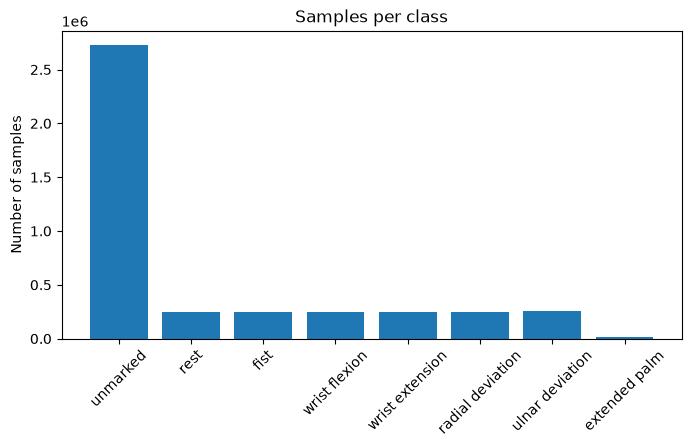

In [142]:
# Number of samples per class
counts = data['class'].value_counts().sort_index()
print(counts)

plt.figure(figsize=(8,4))
plt.bar([class_names[c] for c in counts.index], counts.values)
plt.xticks(rotation=45)
plt.ylabel('Number of samples')
plt.title('Samples per class')
plt.show()

In [143]:
# Number of samples per subject and class
per_subject = pd.crosstab(data['subject'], data['class'])
print('Subjects that performed class 7:', per_subject.index[per_subject[7] > 0].tolist())
per_subject

Subjects that performed class 7: [11, 30]


class,0,1,2,3,4,5,6,7
subject,,,,,,,,
1,78682,7311,6806,7329,6824,7075,7143,0
2,94654,7140,6777,6815,6812,6856,7372,0
3,67770,6443,6301,6486,6421,6278,6086,0
4,72578,6471,6598,6875,7193,7423,7060,0
5,68057,6506,6806,6874,6724,6098,6183,0
6,61128,5814,6243,6663,6688,7094,5989,0
7,82641,7523,7651,8383,8923,8414,9105,0
8,80264,6468,6537,5939,6027,6237,6476,0
9,90407,7083,6019,5838,5776,6050,6474,0


<br> Only 2 subjects performed class 7 (extended palm) <br>

## 3. Time and sampling rate

In [144]:
# Time difference (in ms) between consecutive samples, computed per subject
dt = data.groupby('subject')['time'].diff()
print(dt.value_counts().head(10))

time
1.0     4106924
2.0      108045
3.0       20752
4.0        1252
8.0         180
5.0         165
7.0         148
9.0         143
6.0          77
10.0         75
Name: count, dtype: int64


In [145]:
# A negative time step means the time restarts: this is where the second series of a subject begins
print('Number of time restarts:', (dt < 0).sum())

# Give every sample a series number (1 or 2) within its subject
data['series'] = (dt < 0).groupby(data['subject']).cumsum() + 1
print(data.groupby('subject')['series'].max().value_counts())

Number of time restarts: 36
series
2    36
Name: count, dtype: int64


In [146]:
# Duration of each series in seconds
duration = data.groupby(['subject', 'series'])['time'].agg(['min', 'max'])
duration['seconds'] = (duration['max'] - duration['min']) / 1000
print(duration['seconds'].describe())

count    72.000000
mean     61.263292
std       9.138398
min      47.446000
25%      53.699000
50%      60.163000
75%      65.473250
max      97.142000
Name: seconds, dtype: float64


In [147]:
# How often is a sample exactly the same as the previous one (on all 8 channels)?
same_as_prev = (data[channels].diff() == 0).all(axis=1)
print('Fraction of repeated samples:', same_as_prev.mean())

# Length of the runs of identical samples
run_id = (~same_as_prev).cumsum()
run_lengths = run_id.value_counts()
print('Run length -> number of runs')
print(run_lengths.value_counts().sort_index().head(10))

# Effective sampling rate = number of new (non-repeated) samples per second
total_seconds = dt[dt > 0].sum() / 1000
print('Effective sampling rate (Hz):', (~same_as_prev).sum() / total_seconds)

Fraction of repeated samples: 0.8914742584016119
Run length -> number of runs
count
1     144072
2      42501
3       1967
4       2629
5       5946
6      11215
7      14979
8      15053
9      14161
10      3426
Name: count, dtype: int64
Effective sampling rate (Hz): 104.26807606603283


## 4. Signal values

In [148]:
# The values look quantized: check how many different values a channel has
print('Number of unique values in channel1:', data['channel1'].nunique())
print(np.sort(data['channel1'].unique())[:10])

Number of unique values in channel1: 256
[-0.00128 -0.00127 -0.00126 -0.00125 -0.00124 -0.00123 -0.00122 -0.00121
 -0.0012  -0.00119]


In [149]:
# The sensor has a minimum and a maximum value (8 bits: -0.00128 to +0.00127); samples at these limits are clipped
min_value = data[channels].min().min()
max_value = data[channels].max().max()
clipped = (data[channels] <= min_value) | (data[channels] >= max_value)
print('Minimum value:', min_value, ' maximum value:', max_value)
print('Fraction of clipped samples per channel:')
print(clipped.mean())
print('Fraction of rows with at least one clipped channel:', clipped.any(axis=1).mean())

Minimum value: -0.00128  maximum value: 0.00127
Fraction of clipped samples per channel:
channel1    0.000706
channel2    0.000364
channel3    0.000219
channel4    0.001591
channel5    0.002610
channel6    0.000811
channel7    0.000541
channel8    0.000805
dtype: float64
Fraction of rows with at least one clipped channel: 0.006949892954234248


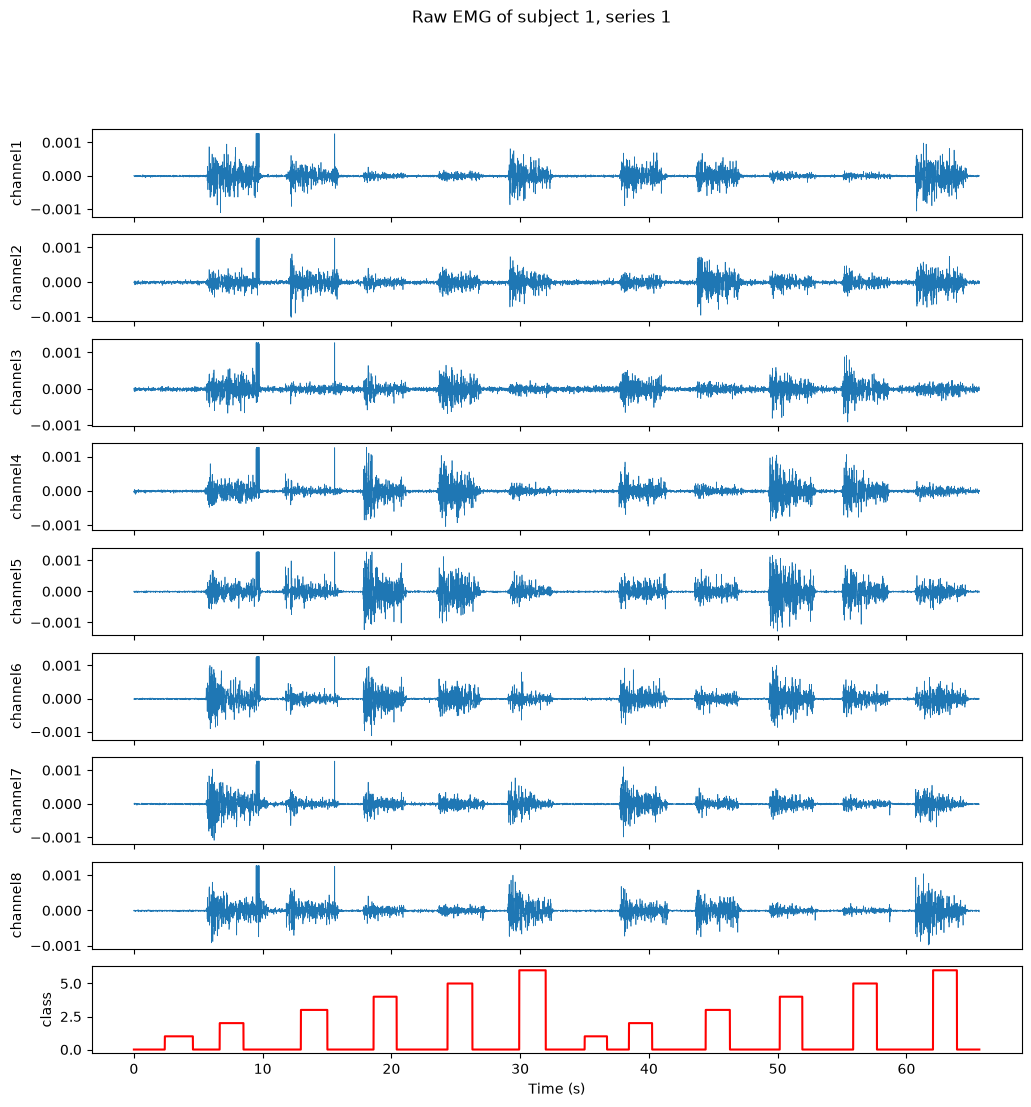

In [150]:
# Plot the raw signals of one subject (series 1) together with the class
s = data[(data['subject'] == 1) & (data['series'] == 1)]

fig, axes = plt.subplots(9, 1, figsize=(12,12), sharex=True)
for i, ch in enumerate(channels):
    axes[i].plot(s['time'] / 1000, s[ch], linewidth=0.5)
    axes[i].set_ylabel(ch)
axes[8].plot(s['time'] / 1000, s['class'], color='red')
axes[8].set_ylabel('class')
axes[8].set_xlabel('Time (s)')
plt.suptitle('Raw EMG of subject 1, series 1')
plt.show()

## 5. Gesture blocks

In [151]:
# Split the data into continuous blocks with the same class (new block at a class, series or subject change)
new_block = (data['class'] != data['class'].shift()) | (data['series'] != data['series'].shift()) | (data['subject'] != data['subject'].shift())
block_id = new_block.cumsum()

blocks = data.groupby(block_id).agg(subject=('subject', 'first'), series=('series', 'first'), cls=('class', 'first'),
                                     start=('time', 'first'), end=('time', 'last'), n_samples=('time', 'size'))
blocks['seconds'] = (blocks['end'] - blocks['start']) / 1000

# Duration of the gesture blocks per class (expected: about 3 seconds)
blocks.groupby('cls')['seconds'].describe()

,count,mean,std,min,25%,50%,75%,max
cls,,,,,,,,
0,940.0,3.023730,1.546262,0.659,2.08750,3.0335,3.79300,34.970
1,144.0,1.799153,0.395730,1.135,1.60350,1.7490,1.90450,4.596
2,144.0,1.746132,0.199073,1.118,1.61925,1.7345,1.84600,2.431
3,144.0,1.793806,0.298868,1.252,1.60600,1.7495,1.91025,3.278
4,144.0,1.806688,0.298462,1.343,1.62000,1.7860,1.89550,3.182
5,144.0,1.806201,0.293618,1.317,1.63600,1.7620,1.95100,2.821
6,144.0,1.817090,0.316997,1.270,1.60000,1.7780,1.96025,3.334
7,8.0,1.765875,0.135242,1.542,1.68125,1.7660,1.86800,1.950


In [152]:
# How many times is each gesture performed per subject and series?
blocks[blocks['cls'] != 0].groupby(['subject', 'series'])['cls'].count().value_counts()

cls
12    68
14     4
Name: count, dtype: int64

## 6. Can single samples separate the classes?

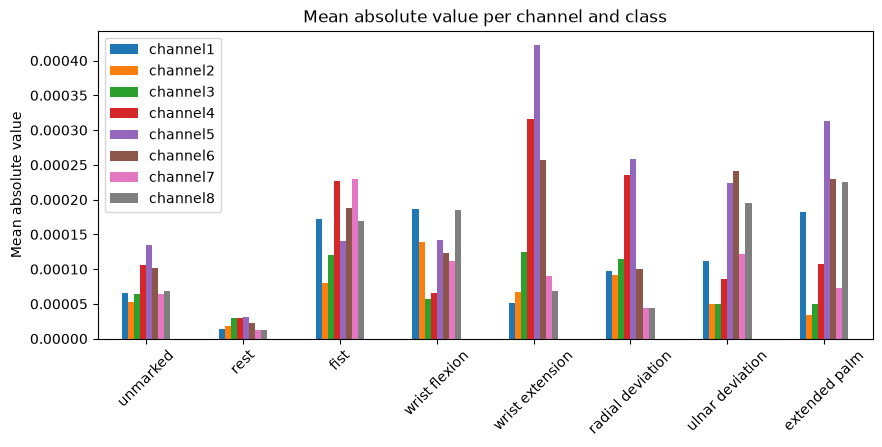

In [153]:
# Average signal strength (mean absolute value) per channel for each class
mav_per_class = data[channels].abs().groupby(data['class']).mean()
mav_per_class.index = [class_names[c] for c in mav_per_class.index]

mav_per_class.plot(kind='bar', figsize=(10,4))
plt.ylabel('Mean absolute value')
plt.title('Mean absolute value per channel and class')
plt.xticks(rotation=45)
plt.show()

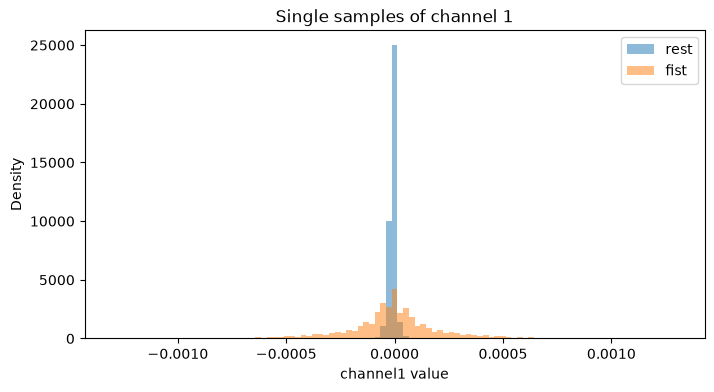

In [154]:
# Distribution of single samples of channel 1 for 'rest' and 'fist'
bins = np.linspace(-0.0013, 0.0013, 100)
plt.figure(figsize=(8,4))
plt.hist(data.loc[data['class'] == 1, 'channel1'], bins=bins, alpha=0.5, density=True, label='rest')
plt.hist(data.loc[data['class'] == 2, 'channel1'], bins=bins, alpha=0.5, density=True, label='fist')
plt.xlabel('channel1 value')
plt.ylabel('Density')
plt.title('Single samples of channel 1')
plt.legend()
plt.show()

## Observations

- **Class balance:** class 0 (unmarked) is about 64% of all rows (2.7 million). Gestures 1-6 are balanced, with about 250,000 rows each.
  Class 7 (extended palm) has only about 14,000 rows.
- **Class 7:** only subjects 11 and 30 performed it, so it cannot be learned or tested for other subjects.
- **Data quality:** there are no missing values. Every subject has exactly 2 series (the time restarts once per subject), and each series lasts about 47-97 s.
- **Sampling rate:** rows are logged about every 1 ms, but 89% of the rows are an exact copy of the previous row.
  The number of new samples is about **104 per second**, much lower than the logging rate (studied further in section 8).
- **Signal values:** every channel has only 256 different values (steps of 0.00001, from -0.00128 to 0.00127), so the signal is
  quantized to 8 bits. A very small part of the samples (at most 0.26% per channel, 0.7% of the rows on at least one channel) is at the
  minimum or maximum value, so clipping is rare.
- **Raw signals (subject 1):** during a gesture the signal is much larger than at rest or during the pause, and different gestures
  activate different channels. There are short spikes on all 8 channels at the same moment (e.g. at about 9.5 s), probably
  artifacts from movement, which reach the clipping value.
- **Block durations:** the description says that every gesture lasts 3 s, but a labelled gesture block is on average only about 1.8 s.
  The unmarked parts (class 0) are about 3 s and probably also contain the transitions into and out of a gesture.
  Every gesture is performed twice per series (12 gesture blocks per series; 14 for the two subjects with class 7).
- **Single samples vs. signal strength:** single samples of 'rest' and 'fist' are both centred around 0 and overlap strongly, so
  one sample tells almost nothing about the gesture. The **mean absolute value** over time, however, is very different
  per class and per channel (e.g. rest is close to 0 everywhere, wrist extension is high on channels 4-6). The information is
  therefore in the signal strength over a short period, which is why we use windows and features (section 9).

## 7. Data preparation

Choices:
- **Class 0 (unmarked) is removed.** It is the pause between gestures (median block of about 3 s) and probably the transitions into and out of a gesture, so it is not one gesture.
- **Class 7 (extended palm) is removed.** Only subjects 11 and 30 performed it, so there is too little data to learn it and it cannot be tested on other subjects.

In [155]:
# Give every sample the number of the gesture block it belongs to (computed in section 5)
data['block'] = block_id

In [156]:
# Remove unmarked data (class 0) and extended palm (class 7)
data_prep = data[(data['class'] != 0) & (data['class'] != 7)].reset_index(drop=True)

print('Samples before:', len(data))
print('Samples after:', len(data_prep))
print(data_prep['class'].value_counts().sort_index())

Samples before: 4237907
Samples after: 1499054
class
1    250055
2    243193
3    249494
4    251570
5    251733
6    253009
Name: count, dtype: int64


In [157]:
# Check that every subject still has all 6 gestures, performed twice in each series (12 blocks per series)
blocks_per_series = data_prep.groupby(['subject', 'series'])['block'].nunique()
print(blocks_per_series.value_counts())

block
12    72
Name: count, dtype: int64


In [158]:
# Keep only the columns we need
data_prep = data_prep[['subject', 'series', 'block', 'time'] + channels + ['class']]
data_prep

,subject,series,block,time,channel1,channel2,channel3,channel4,channel5,channel6,channel7,channel8,class
0,1,1,2,2400,-0.00001,0.00000,-0.00001,0.00000,0.00000,-0.00001,-0.00001,0.00001,1
1,1,1,2,2401,-0.00001,-0.00002,0.00000,-0.00001,-0.00001,-0.00001,-0.00003,-0.00002,1
2,1,1,2,2402,-0.00001,-0.00002,0.00000,-0.00001,-0.00001,-0.00001,-0.00003,-0.00002,1
3,1,1,2,2403,-0.00001,-0.00002,0.00000,-0.00001,-0.00001,-0.00001,-0.00003,-0.00002,1
4,1,1,2,2404,-0.00001,-0.00002,0.00000,-0.00001,-0.00001,-0.00001,-0.00003,-0.00002,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1499049,36,2,1811,50226,0.00009,0.00001,0.00003,0.00001,-0.00003,-0.00008,0.00004,0.00000,6
1499050,36,2,1811,50227,0.00009,0.00001,0.00003,0.00001,-0.00003,-0.00008,0.00004,0.00000,6
1499051,36,2,1811,50228,0.00009,0.00001,0.00003,0.00001,-0.00003,-0.00008,0.00004,0.00000,6
1499052,36,2,1811,50229,0.00014,0.00003,-0.00001,0.00001,-0.00012,0.00006,-0.00007,-0.00013,6


## 8. Data cleaning: removing repeated samples

About 89% of the rows are an exact copy of the previous row (all 8 channels identical).

**Assumption:** these copies are not new measurements, but the last received values written again by the recording software
(rows are logged about every 1 ms, while new values arrive only about 105 times per second).
This is not stated in the project description; it is our interpretation, based on the following evidence:
- 8 independent, noisy channels are rarely exactly equal to the previous sample by chance.
- The copies come in runs of typically 5-10 rows.
- After removing them, the sampling rate is about 105 Hz for **every** class (checked below). If the copies were real
  measurements that happened to be equal, they would be much more common at rest (small signal) than during a gesture.

Under this assumption the copies carry no information about the muscle: they make a window look longer than the real
signal is and they distort features such as waveform length and frequency features.
We therefore keep only the samples that differ from the previous sample **in the same block**.

In [159]:
# A sample is a repeat if all 8 channels are equal to the previous sample in the same block
previous = data_prep.groupby('block')[channels].shift()
is_repeat = (data_prep[channels] == previous).all(axis=1)
print('Fraction of repeated samples:', is_repeat.mean())

Fraction of repeated samples: 0.8910779731750824


In [160]:
# Keep only the new (non-repeated) samples
data_clean = data_prep[~is_repeat].reset_index(drop=True)

print('Samples before:', len(data_prep))
print('Samples after:', len(data_clean))
print(data_clean['class'].value_counts().sort_index())

Samples before: 1499054
Samples after: 163280
class
1    27352
2    26651
3    27016
4    27456
5    27244
6    27561
Name: count, dtype: int64


count    162416.000000
mean          9.504538
std           8.390471
min           1.000000
25%           1.000000
50%           8.000000
75%          15.000000
max         151.000000
Name: time, dtype: float64


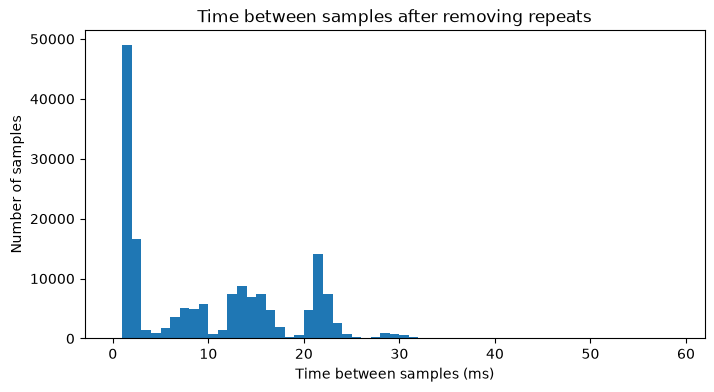

In [161]:
# Time (in ms) between the samples that are left, within each block
dt_clean = data_clean.groupby('block')['time'].diff()
print(dt_clean.describe())

plt.figure(figsize=(8,4))
plt.hist(dt_clean, bins=np.arange(0, 60, 1))
plt.xlabel('Time between samples (ms)')
plt.ylabel('Number of samples')
plt.title('Time between samples after removing repeats')
plt.show()

In [162]:
# Effective sampling rate per block = number of samples / duration of the block
per_block = data_clean.groupby('block').agg(cls=('class', 'first'), n_samples=('time', 'size'),
                                            start=('time', 'first'), end=('time', 'last'))
per_block['rate_hz'] = per_block['n_samples'] / ((per_block['end'] - per_block['start']) / 1000)

# If real (not copied) samples were removed during rest, the rate of class 1 would be lower than the others
per_block.groupby('cls')['rate_hz'].describe()

,count,mean,std,min,25%,50%,75%,max
cls,,,,,,,,
1,144.0,105.934563,8.066930,74.449077,100.806754,105.438569,111.894603,126.962142
2,144.0,106.485327,8.279762,86.725664,100.540946,106.008981,111.647901,137.181875
3,144.0,104.975579,8.260304,86.862106,99.408251,104.618900,110.259679,126.477541
4,144.0,105.966068,8.643368,79.740106,100.355534,105.066003,110.856881,129.690949
5,144.0,105.180912,8.314292,85.904416,100.122482,103.755169,109.698766,130.528587
6,144.0,105.832242,7.875320,88.453747,100.456039,105.658101,110.151852,125.296912


In [163]:
# Number of samples per gesture block after cleaning (this limits the window length)
print(per_block['n_samples'].describe())

count    864.000000
mean     188.981481
std       36.140830
min      119.000000
25%      166.000000
50%      185.000000
75%      204.000000
max      487.000000
Name: n_samples, dtype: float64


In [164]:
# Large gaps: no new sample for more than 50 ms
print('Gaps longer than 50 ms:', (dt_clean > 50).sum(), 'out of', dt_clean.count())

Gaps longer than 50 ms: 56 out of 162416


**Extra test of the assumption.** If the repeats were real measurements that are equal by chance, they would be common
when the signal is small (few possible values) and very rare when the signal is large (8 channels changing a lot).
If they are copies made by the recording software, the fraction of repeats does not depend on the signal size.
We split all samples into 10 equally large groups by signal size (mean absolute value over the 8 channels) and compare the fraction of repeats.

(-0.00099875, 2e-05]    0.891818
(2e-05, 4.25e-05]       0.890142
(4.25e-05, 6.38e-05]    0.890960
(6.38e-05, 8.38e-05]    0.891878
(8.38e-05, 0.000105]    0.890604
(0.000105, 0.000128]    0.891401
(0.000128, 0.000156]    0.891619
(0.000156, 0.000194]    0.890944
(0.000194, 0.000252]    0.891107
(0.000252, 0.00117]     0.890316
dtype: float64


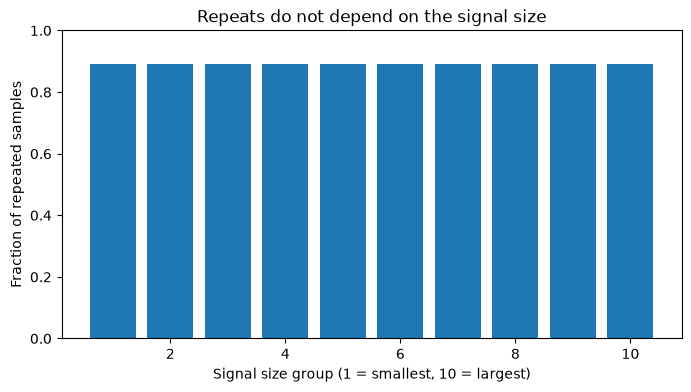

In [165]:
# Signal size of every sample: mean absolute value over the 8 channels
amplitude = data_prep[channels].abs().mean(axis=1)

# Split the samples into 10 groups (deciles) from smallest to largest signal
amplitude_group = pd.qcut(amplitude, 10)

# Fraction of repeated samples in each group
repeats_per_group = is_repeat.groupby(amplitude_group).mean()
print(repeats_per_group)

plt.figure(figsize=(8,4))
plt.bar(range(1, 11), repeats_per_group.values)
plt.ylim(0, 1)
plt.xlabel('Signal size group (1 = smallest, 10 = largest)')
plt.ylabel('Fraction of repeated samples')
plt.title('Repeats do not depend on the signal size')
plt.show()

Results:
- After removing repeats, about 163,000 samples remain (about 27,000 per class).
- The effective sampling rate is about **105 Hz** and is the same for every class, so there is no sign that removing repeats removed real samples during rest (this supports the assumption above).
- The fraction of repeats is 89% for every signal size, from the smallest to the largest signals. Real equal-by-chance samples would almost disappear for large signals, so this strongly supports the assumption that the repeats are copies.
- The time between samples is irregular: new samples often arrive in pairs (1-2 ms apart) followed by a pause (about 8-21 ms).
- A gesture block contains about 185 samples (minimum 119). Gaps longer than 50 ms are very rare and are ignored.

Decision: we treat the cleaned samples as one sequence at about 105 Hz and define windows by a **number of samples**.

## 9. Windowing and feature construction

A single EMG sample says almost nothing about the gesture (section 6): the information is in the signal over a short period.
We therefore cut every gesture block into **windows** and compute features per window and per channel.

- **Window length:** 20 samples (about 190 ms at 105 Hz), with 50% overlap (a new window every 10 samples).
  A gesture block has at least 119 samples, so every block gives several windows. Windows never cross block borders.
- **Features** (computed for each of the 8 channels, so 5 x 8 = 40 features per window):
  - **MAV** (mean absolute value): average signal strength.
  - **RMS** (root mean square): signal power.
  - **WL** (waveform length, per sample): average size of the jumps between consecutive samples.
  - **ZC** (zero crossings, per sample): how often the signal changes sign.
  - **MNF** (mean frequency): average frequency of the power spectrum of the window.
- All features are **averages per sample**, not sums, so they do not depend on the number of samples in a window.
- MNF assumes evenly spaced samples at 105 Hz; our samples are not exactly evenly spaced (section 8), so MNF is only an approximation.

In [166]:
# Settings
fs = 105            # effective sampling rate in Hz (section 8)
window_size = 20    # samples per window (about 190 ms)
step = 10           # a new window every 10 samples (50% overlap)

feature_types = ['MAV', 'RMS', 'WL', 'ZC', 'MNF']
feature_names = [f'{f}_ch{i}' for f in feature_types for i in range(1, 9)]
print('Number of features:', len(feature_names))

Number of features: 40


In [167]:
def extract_features(window, fs):
    # window: array of shape (number of samples, 8 channels); every feature gives one value per channel
    mav = np.mean(np.abs(window), axis=0)
    rms = np.sqrt(np.mean(window**2, axis=0))
    wl = np.mean(np.abs(np.diff(window, axis=0)), axis=0)
    zc = np.mean(window[1:] * window[:-1] < 0, axis=0)

    # Mean frequency: weighted average of the frequencies, weighted by the power at each frequency
    power = np.abs(np.fft.rfft(window - window.mean(axis=0), axis=0))**2
    freqs = np.fft.rfftfreq(len(window), d=1/fs)
    mnf = np.sum(freqs[:, None] * power, axis=0) / (np.sum(power, axis=0) + 1e-20)

    return np.concatenate([mav, rms, wl, zc, mnf])

In [168]:
def make_feature_table(data, window_size, step, fs):
    # Cut every gesture block into windows and compute the features of each window
    rows = []
    for block, b in data.groupby('block'):
        signals = b[channels].values
        for start in range(0, len(b) - window_size + 1, step):
            window = signals[start:start + window_size]
            rows.append(list(extract_features(window, fs)) + [b['class'].iloc[0], b['subject'].iloc[0], b['series'].iloc[0], block])
    return pd.DataFrame(rows, columns=feature_names + ['class', 'subject', 'series', 'block'])

features = make_feature_table(data_clean, window_size, step, fs)
print('Shape of the feature table:', features.shape)
print(features['class'].value_counts().sort_index())

Shape of the feature table: (15069, 44)
class
1    2523
2    2461
3    2491
4    2537
5    2513
6    2544
Name: count, dtype: int64


In [169]:
features.head()

,MAV_ch1,MAV_ch2,MAV_ch3,MAV_ch4,MAV_ch5,MAV_ch6,MAV_ch7,MAV_ch8,RMS_ch1,RMS_ch2,...,MNF_ch3,MNF_ch4,MNF_ch5,MNF_ch6,MNF_ch7,MNF_ch8,class,subject,series,block
0,0.000013,0.000017,0.000022,0.000015,0.000011,0.000010,0.000012,0.000012,0.000015,0.000023,...,25.379153,30.307469,35.088014,24.641942,30.107122,25.303318,1,1,1,2
1,0.000012,0.000019,0.000026,0.000014,0.000012,0.000013,0.000010,0.000012,0.000015,0.000023,...,32.825763,29.016135,35.681841,23.681805,25.491205,24.853026,1,1,1,2
2,0.000011,0.000016,0.000027,0.000011,0.000015,0.000014,0.000012,0.000011,0.000014,0.000022,...,38.383079,32.598867,30.216709,28.782141,32.119405,27.544078,1,1,1,2
3,0.000010,0.000015,0.000025,0.000016,0.000014,0.000011,0.000011,0.000013,0.000014,0.000021,...,34.024739,29.275860,31.570620,29.036083,25.123811,27.501409,1,1,1,2
4,0.000010,0.000016,0.000025,0.000016,0.000011,0.000008,0.000011,0.000012,0.000013,0.000024,...,34.786789,23.672447,27.157392,26.155452,28.320771,28.610133,1,1,1,2


## 10. Train / validation / test split (by subject)

The split is made **by subject**: all windows of one subject go to the same set. Windows of the same subject (and especially
of the same block) are very similar, so a random split of windows would put almost identical windows in training and test data
and the scores would be too optimistic. Splitting by subject tests what we want to know: does the model work for a **new person**?

- **Test set** (7 subjects, about 20%): put aside now and not used until the final evaluation (Lecture 6: the model must never see the test data).
- **Validation set** (7 subjects): used to compare feature sets and settings.
- **Training set** (22 subjects): used to fit the scaler and the models.

In [170]:
# Randomly divide the 36 subjects over the three sets
np.random.seed(42)
subjects = np.random.permutation(np.arange(1, 37))
test_subjects = subjects[:7]
val_subjects = subjects[7:14]
train_subjects = subjects[14:]

print('Test subjects:', np.sort(test_subjects))
print('Validation subjects:', np.sort(val_subjects))
print('Training subjects:', np.sort(train_subjects))

Test subjects: [14 17 22 27 31 32 36]
Validation subjects: [ 1  5  9 10 13 18 35]
Training subjects: [ 2  3  4  6  7  8 11 12 15 16 19 20 21 23 24 25 26 28 29 30 33 34]


In [171]:
train = features[features['subject'].isin(train_subjects)]
val = features[features['subject'].isin(val_subjects)]
test = features[features['subject'].isin(test_subjects)]

print('Training windows:', len(train))
print('Validation windows:', len(val))
print('Test windows:', len(test))

Training windows: 9165
Validation windows: 3052
Test windows: 2852


## 11. Feature analysis (training subjects only)

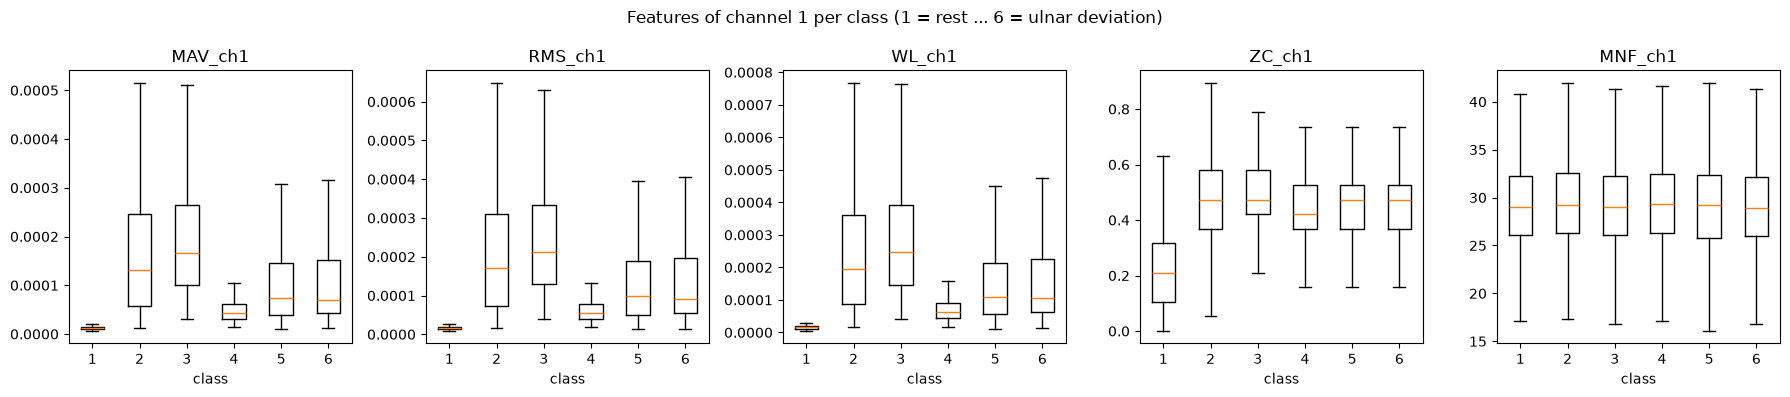

In [172]:
# Distribution of each feature type per class, for one channel
channel = 1
fig, axes = plt.subplots(1, 5, figsize=(18,4))
for i, f in enumerate(feature_types):
    column = f'{f}_ch{channel}'
    axes[i].boxplot([train.loc[train['class'] == c, column] for c in range(1, 7)], showfliers=False)
    axes[i].set_title(column)
    axes[i].set_xlabel('class')
plt.suptitle(f'Features of channel {channel} per class (1 = rest ... 6 = ulnar deviation)')
plt.tight_layout()
plt.show()

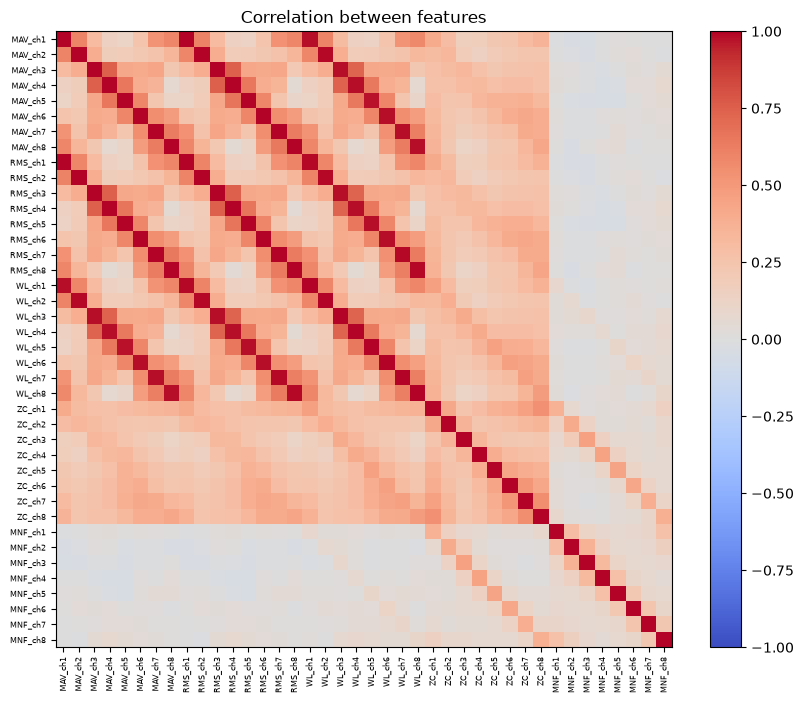

In [173]:
# Correlation matrix of all 40 features
corr_matrix = train[feature_names].corr()

plt.figure(figsize=(10,8))
plt.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar()
plt.xticks(range(len(feature_names)), feature_names, rotation=90, fontsize=6)
plt.yticks(range(len(feature_names)), feature_names, fontsize=6)
plt.title('Correlation between features')
plt.show()

In [174]:
# Average correlation between two feature types (on the same channel)
type_corr = pd.DataFrame(index=feature_types, columns=feature_types, dtype=float)
for a in feature_types:
    for b in feature_types:
        type_corr.loc[a, b] = np.mean([corr_matrix.loc[f'{a}_ch{i}', f'{b}_ch{i}'] for i in range(1, 9)])
type_corr.round(2)

,MAV,RMS,WL,ZC,MNF
MAV,1.00,1.00,0.98,0.37,-0.01
RMS,1.00,1.00,0.98,0.37,-0.01
WL,0.98,0.98,1.00,0.44,0.09
ZC,0.37,0.37,0.44,1.00,0.41
MNF,-0.01,-0.01,0.09,0.41,1.00


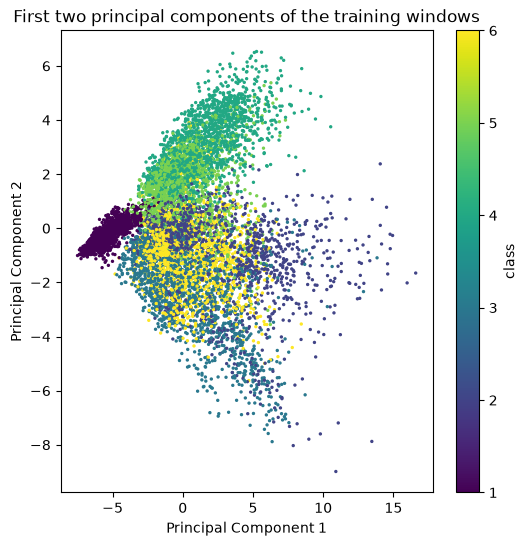

In [175]:
# PCA: project the standardized features onto the first 2 principal components
scaler = StandardScaler()
scaler.fit(train[feature_names])
x_train_scaled = scaler.transform(train[feature_names])

pca = PCA(n_components=2)
x_pca = pca.fit_transform(x_train_scaled)

plt.figure(figsize=(6,6))
plt.scatter(x_pca[:,0], x_pca[:,1], c=train['class'], cmap='viridis', s=2)
plt.colorbar(label='class')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('First two principal components of the training windows')
plt.show()

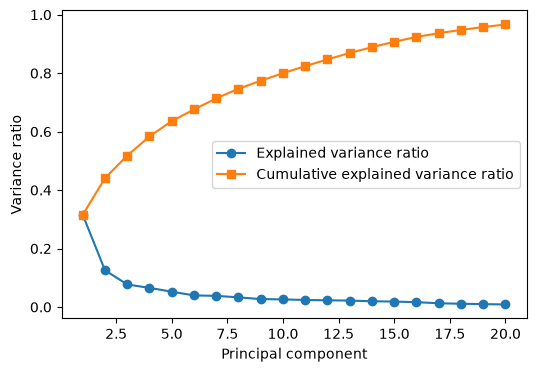

In [176]:
# Explained variance of the first 20 principal components
pca_20 = PCA(n_components=20)
pca_20.fit(x_train_scaled)

explained_var = pca_20.explained_variance_ratio_
cumulative_var = np.cumsum(explained_var)

plt.figure(figsize=(6,4))
plt.plot(range(1, 21), explained_var, marker='o', label='Explained variance ratio')
plt.plot(range(1, 21), cumulative_var, marker='s', label='Cumulative explained variance ratio')
plt.xlabel('Principal component')
plt.ylabel('Variance ratio')
plt.legend()
plt.show()

## 12. Standardization and feature selection

We compare feature sets on the **validation subjects** (Lectures 4 and 6). For every feature set:
1. A `StandardScaler` is fitted on the **training subjects only** and used to standardize training and validation data
   (fitting it on validation or test data would leak information).
2. A simple multi-class logistic regression (Lecture 3) is trained on the training subjects.
3. The predictions on the validation subjects are scored with the metrics from CodeLabs 3 and 4:
   **accuracy, precision, recall and F1 score** (macro average = the average over the 6 classes, every class counts equally),
   and a **confusion matrix** to see which gestures are confused.

The classes are balanced (about 2,500 windows each), so accuracy and F1 give similar values. For the selection we use the
**macro F1 score**, because it combines precision and recall and would also stay fair if a class were smaller.
The test subjects are not used.

In [177]:
def columns_of(types):
    # All column names of the given feature types, e.g. ['MAV'] -> ['MAV_ch1', ..., 'MAV_ch8']
    return [f'{t}_ch{i}' for t in types for i in range(1, 9)]

def evaluate_features(columns, train, val):
    # Fit the scaler and a logistic regression on the training subjects, score on the validation subjects
    scaler = StandardScaler()
    scaler.fit(train[columns])          # fitted on training subjects only
    model = LogisticRegression(max_iter=3000)
    model.fit(scaler.transform(train[columns]), train['class'])
    y_pred = model.predict(scaler.transform(val[columns]))

    scores = {'accuracy': accuracy_score(val['class'], y_pred),
              'precision': precision_score(val['class'], y_pred, average='macro'),
              'recall': recall_score(val['class'], y_pred, average='macro'),
              'f1': f1_score(val['class'], y_pred, average='macro')}
    return scores, y_pred

     accuracy  precision  recall     f1
MAV     0.871      0.877   0.872  0.873
RMS     0.865      0.870   0.867  0.866
WL      0.871      0.877   0.872  0.873
ZC      0.472      0.457   0.469  0.460
MNF     0.208      0.207   0.208  0.202


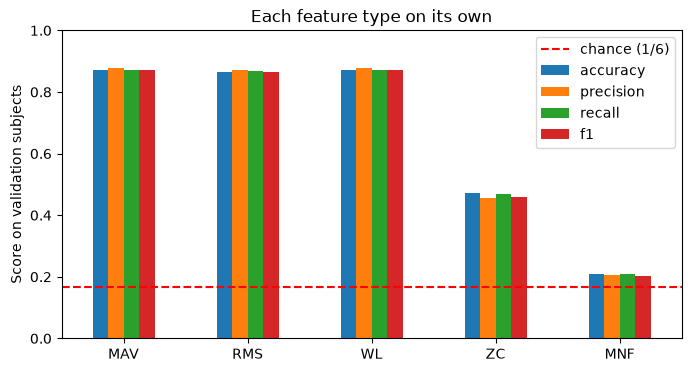

In [178]:
# Scores of every feature type on its own
results_per_type = pd.DataFrame(index=feature_types, columns=['accuracy', 'precision', 'recall', 'f1'], dtype=float)
for f in feature_types:
    scores, y_pred = evaluate_features(columns_of([f]), train, val)
    results_per_type.loc[f] = scores
print(results_per_type.round(3))

results_per_type.plot(kind='bar', figsize=(8,4))
plt.axhline(1/6, color='r', linestyle='--', label='chance (1/6)')
plt.ylim(0, 1)
plt.ylabel('Score on validation subjects')
plt.title('Each feature type on its own')
plt.xticks(rotation=0)
plt.legend()
plt.show()

['MAV'] accuracy: 0.871 precision: 0.877 recall: 0.872 f1: 0.873
['MAV', 'WL'] accuracy: 0.875 precision: 0.881 recall: 0.876 f1: 0.877
['MAV', 'WL', 'ZC'] accuracy: 0.870 precision: 0.876 recall: 0.871 f1: 0.871
['MAV', 'WL', 'ZC', 'MNF'] accuracy: 0.870 precision: 0.874 recall: 0.871 f1: 0.871
['MAV', 'WL', 'ZC', 'MNF', 'RMS'] accuracy: 0.866 precision: 0.870 recall: 0.867 f1: 0.867


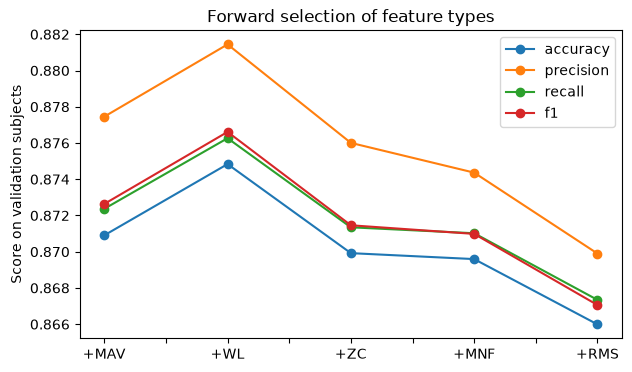

In [179]:
# Forward selection: start with no features and add, one at a time, the feature type that gives the highest validation F1 score
selected = []
remaining = feature_types.copy()
forward_results = []

while len(remaining) > 0:
    f1_scores = [evaluate_features(columns_of(selected + [f]), train, val)[0]['f1'] for f in remaining]
    best = remaining[np.argmax(f1_scores)]
    selected.append(best)
    remaining.remove(best)
    scores, y_pred = evaluate_features(columns_of(selected), train, val)
    forward_results.append(scores)
    print(selected, ' '.join('%s: %.3f' % (k, v) for k, v in scores.items()))

forward_results = pd.DataFrame(forward_results, index=['+' + s for s in selected])
forward_results.plot(marker='o', figsize=(7,4))
plt.ylabel('Score on validation subjects')
plt.title('Forward selection of feature types')
plt.show()

accuracy: 0.871 precision: 0.877 recall: 0.872 f1: 0.873


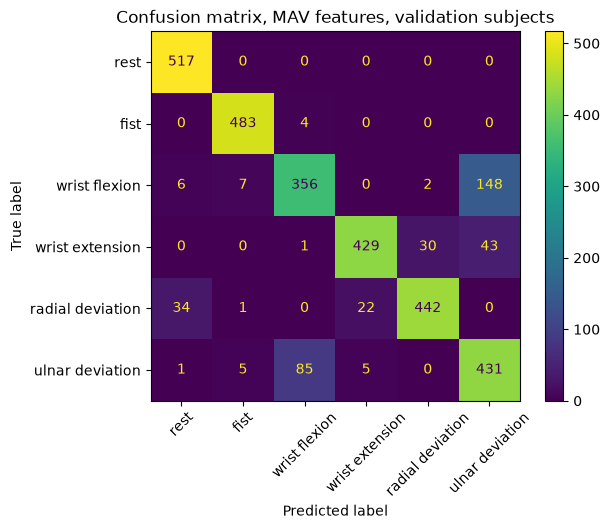

In [180]:
# Confusion matrix of the selected feature set (MAV) on the validation subjects
scores, y_pred = evaluate_features(columns_of(['MAV']), train, val)
print(' '.join('%s: %.3f' % (k, v) for k, v in scores.items()))

conf_matrix = confusion_matrix(val['class'], y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix, display_labels=[class_names[c] for c in range(1, 7)])
disp.plot(xticks_rotation=45)
plt.title('Confusion matrix, MAV features, validation subjects')
plt.show()

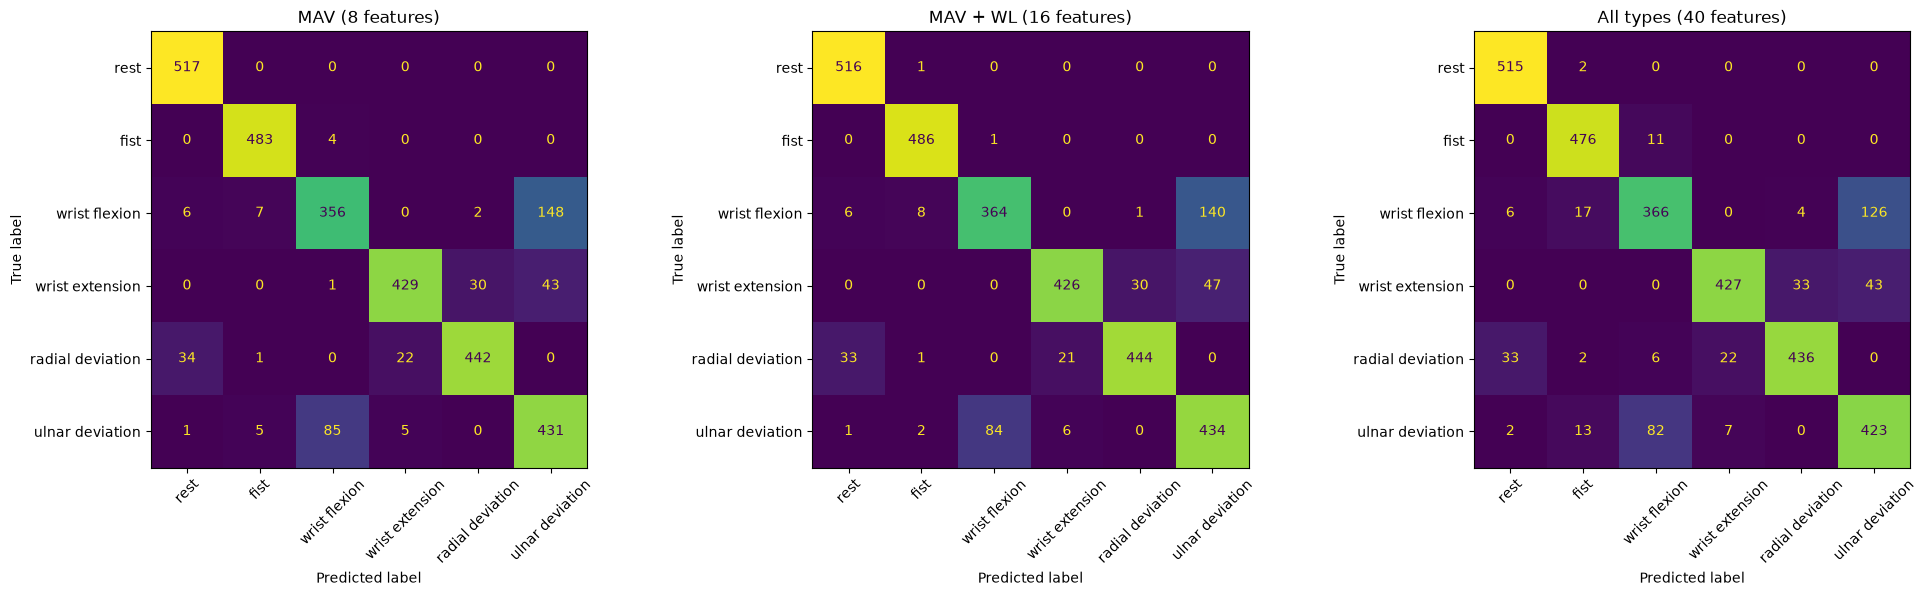

,accuracy,precision,recall,f1
MAV (8 features),0.871,0.877,0.872,0.873
MAV + WL (16 features),0.875,0.881,0.876,0.877
All types (40 features),0.866,0.870,0.867,0.867


In [181]:
# Compare feature sets with fewer and more features: scores and confusion matrices on the validation subjects
feature_sets = {'MAV (8 features)': ['MAV'],
                'MAV + WL (16 features)': ['MAV', 'WL'],
                'All types (40 features)': feature_types}

results_sets = pd.DataFrame(index=feature_sets.keys(), columns=['accuracy', 'precision', 'recall', 'f1'], dtype=float)
fig, axes = plt.subplots(1, 3, figsize=(20,6))
for ax, (name, types) in zip(axes, feature_sets.items()):
    scores, y_pred = evaluate_features(columns_of(types), train, val)
    results_sets.loc[name] = scores
    conf_matrix = confusion_matrix(val['class'], y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=conf_matrix, display_labels=[class_names[c] for c in range(1, 7)])
    disp.plot(ax=ax, xticks_rotation=45, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

results_sets.round(3)

In [182]:
# Effect of the window length (with MAV features, 50% overlap)
results_per_size = []
for size in [10, 20, 30, 40]:
    f = make_feature_table(data_clean, size, size // 2, fs)
    scores, y_pred = evaluate_features(columns_of(['MAV']), f[f['subject'].isin(train_subjects)], f[f['subject'].isin(val_subjects)])
    scores['windows'] = len(f)
    results_per_size.append(scores)
results_per_size = pd.DataFrame(results_per_size, index=['%d samples (%.0f ms)' % (s, s / fs * 1000) for s in [10, 20, 30, 40]])
results_per_size.round(3)

,accuracy,precision,recall,f1,windows
10 samples (95 ms),0.866,0.872,0.867,0.867,31452
20 samples (190 ms),0.871,0.877,0.872,0.873,15069
30 samples (286 ms),0.872,0.881,0.874,0.875,9613
40 samples (381 ms),0.868,0.878,0.870,0.871,6905


Results of the feature analysis and selection (scores on the validation subjects, macro averages):
- **MAV, RMS and WL are almost the same information** (correlation 0.98-1.00). On their own they all score about 0.87
  (accuracy, precision, recall and F1). Keeping all three adds features but no information.
- **ZC is weaker** (F1 0.46 on its own) and **MNF is close to chance** (F1 0.20, chance = 0.17).
  For MNF this is expected: with 20 unevenly spaced samples the frequency estimate is very rough.
- **PCA:** rest forms a separate cluster; the other gestures overlap in 2 dimensions. The first 2 components explain about 44%
  of the variance, so the information is spread over many features.
- **Forward selection:** MAV alone F1 0.873, MAV + WL 0.877; adding more feature types does not help (0.867-0.871).
  The difference between MAV and MAV + WL (0.4%, about 12 of 3052 windows) is too small to be meaningful.
- **Confusion matrix (MAV):** rest and fist are almost perfect. The main error is **wrist flexion vs. ulnar deviation**
  (148 flexion windows predicted as ulnar deviation, 85 the other way round), followed by radial deviation vs. rest/extension.
  Precision and recall are close to each other, so no class is systematically over- or under-predicted.
- **Window length:** 10-40 samples give almost the same scores (F1 0.867-0.875). We keep **20 samples (about 190 ms)**:
  short enough for real-time use and it gives more windows than longer windows.

Decision: **MAV** (8 features) is the main feature set, because simpler is better when the scores are the same (Lecture 6, parsimony).
This selection was made with a linear model; a nonlinear model (Task 2) might still use ZC or MNF, so we also keep the
full set of 40 features as a second candidate and compare both in Task 2.


## Summary of Task 1

| Step | Choice | Reason |
|---|---|---|
| Preparation | Remove class 0 (unmarked) and class 7 (extended palm) | Class 0 is pauses and transitions, not one gesture; class 7 was performed by only 2 subjects |
| Cleaning | Remove repeated rows (89%) | They are copies written by the recording software; real sampling rate is about 105 Hz |
| Windowing | 20 samples (about 190 ms), 50% overlap, inside one gesture block | Single samples carry almost no information; 10-40 samples score the same |
| Feature construction | MAV, RMS, WL, ZC, MNF per channel (40 features) | Common time- and frequency-domain EMG features |
| Split | By subject: 22 train, 7 validation, 7 test | Tests whether the model works for a new person and avoids leakage between similar windows |
| Standardization | `StandardScaler` fitted on training subjects only | Features have very different scales; fitting on other sets would leak information |
| Feature selection | **MAV (8 features)** as main set, all 40 features as second candidate | MAV, RMS and WL are nearly identical (correlation 0.98-1.00); more features do not improve the linear model |

Result: logistic regression with MAV features reaches **macro F1 0.873** on the validation subjects (chance = 0.17).
The output of Task 1 is the table `features` (15,069 windows) and the subject split, which are the input for Task 2.

# Task 2: Neural network (MLP)

## 13. A first MLP on the MAV features

We start with a fully connected neural network (multi-layer perceptron, Lecture 5) from scikit-learn, with reasonable
default settings. It is trained and scored in exactly the same way as the logistic regression of section 12
(training subjects -> validation subjects, MAV features), so the two scores can be compared directly.

Choices:
- **Pipeline (`StandardScaler` + `MLPClassifier`):** an MLP is trained with gradient descent, which works badly when the inputs
  have very different scales, so the features are standardized. Inside a pipeline the scaler is fitted on the training subjects only,
  as in Task 1, so no information from the validation subjects leaks into the model.
- **Two hidden layers (64 and 32 neurons):** two hidden layers make it a deep network (required by the project). The network is
  kept small because there are only 8 inputs and about 9,000 training windows; a large network would overfit.
- **ReLU activation and the Adam optimizer** with mini-batches (the scikit-learn defaults, Lecture 5).
- **`alpha = 1e-4`** (default L2 regularization, which keeps the weights small).
- **No `early_stopping=True`:** scikit-learn would then hold out a random 10% of the training *windows*. Windows of the same subject
  and block would end up on both sides, which goes against the subject-wise split of section 10. Instead, training stops when the
  training loss no longer improves (default: 10 epochs without improvement), with at most 500 epochs.
- **`random_state = 42`:** the initial weights are random; fixing the seed makes the result reproducible.
- The test subjects are not used.

In [183]:


def scores_of(y_true, y_pred):
    # The same metrics as in section 12 (macro averages over the 6 classes)
    return {'accuracy': accuracy_score(y_true, y_pred),
            'precision': precision_score(y_true, y_pred, average='macro'),
            'recall': recall_score(y_true, y_pred, average='macro'),
            'f1': f1_score(y_true, y_pred, average='macro')}

mav_columns = columns_of(['MAV'])

mlp = Pipeline([('scaler', StandardScaler()),
                ('mlp', MLPClassifier(hidden_layer_sizes=(64, 32), activation='relu', solver='adam',
                                      alpha=1e-4, max_iter=500, early_stopping=False, random_state=42))])

# Train on the training subjects, score on the validation subjects
mlp.fit(train[mav_columns], train['class'])
y_pred_mlp = mlp.predict(val[mav_columns])
scores_mlp = scores_of(val['class'], y_pred_mlp)

print('Epochs trained:', mlp.named_steps['mlp'].n_iter_)
print(' '.join('%s: %.3f' % (k, v) for k, v in scores_mlp.items()))

Epochs trained: 296
accuracy: 0.889 precision: 0.891 recall: 0.889 f1: 0.888


                           accuracy  precision  recall     f1
Logistic regression (MAV)     0.871      0.877   0.872  0.873
MLP 64-32 (MAV)               0.889      0.891   0.889  0.888


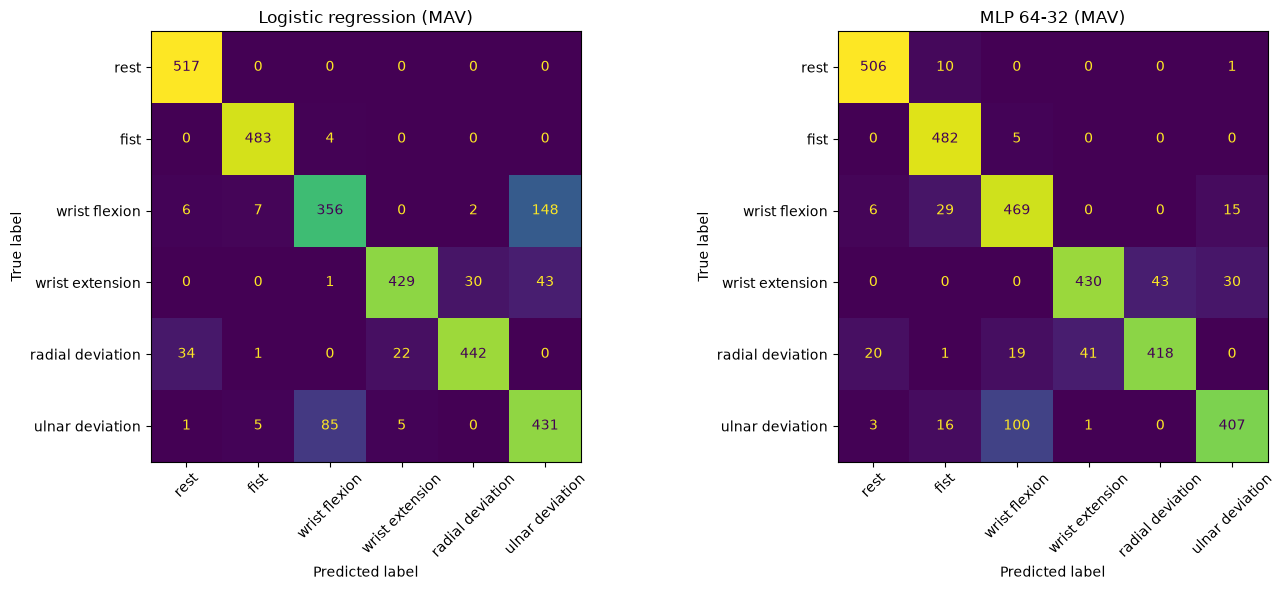

In [184]:
# Compare with the logistic regression baseline of section 12 (same features, same subjects)
scores_lr, y_pred_lr = evaluate_features(mav_columns, train, val)

comparison = pd.DataFrame([scores_lr, scores_mlp], index=['Logistic regression (MAV)', 'MLP 64-32 (MAV)'])
print(comparison.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14,6))
for ax, (name, y_pred) in zip(axes, [('Logistic regression (MAV)', y_pred_lr), ('MLP 64-32 (MAV)', y_pred_mlp)]):
    disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(val['class'], y_pred),
                                  display_labels=[class_names[c] for c in range(1, 7)])
    disp.plot(ax=ax, xticks_rotation=45, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

In [185]:
# Overfitting check: accuracy on the training subjects vs. the validation subjects
print('MLP accuracy on training subjects:  %.3f' % mlp.score(train[mav_columns], train['class']))
print('MLP accuracy on validation subjects: %.3f' % scores_mlp['accuracy'])

# Macro F1 score per validation subject: are the differences between the two models the same for every person?
per_subject_f1 = pd.DataFrame(index=np.sort(val_subjects), columns=['Logistic regression', 'MLP'], dtype=float)
for s in per_subject_f1.index:
    mask = (val['subject'] == s).values
    per_subject_f1.loc[s] = [f1_score(val['class'][mask], y_pred_lr[mask], average='macro'),
                             f1_score(val['class'][mask], y_pred_mlp[mask], average='macro')]
per_subject_f1.index.name = 'subject'
per_subject_f1.round(3)

MLP accuracy on training subjects:  0.982
MLP accuracy on validation subjects: 0.889


,Logistic regression,MLP
subject,,
1,0.663,0.744
5,0.857,0.914
9,0.994,0.971
10,0.788,0.898
13,0.848,0.951
18,0.963,0.874
35,0.853,0.776


Results (validation subjects, MAV features, macro averages):
- The MLP reaches **F1 0.888** (accuracy 0.889), against **0.873** for logistic regression: about 1.5 percentage points better
  (about 50 of the 3052 validation windows). Training stopped after 296 epochs because the training loss stopped improving.
- **Confusion matrix:** the main error of logistic regression, wrist flexion predicted as ulnar deviation (148 windows), almost disappears
  with the MLP (15 windows). The opposite error, ulnar deviation predicted as wrist flexion, remains (100 windows), and the MLP makes
  some new errors (e.g. wrist flexion predicted as fist, 29 windows). A nonlinear model can draw curved class borders, which helps
  for gestures that use similar muscles.
- **Overfitting:** the MLP scores 0.98 accuracy on the training subjects but 0.89 on the validation subjects. Part of this gap is the
  difference between people, but it also suggests that the network is too flexible or trained too long. The regularization (`alpha`),
  the network size and the number of epochs are therefore tuned in the next step.
- **Per subject** the picture is mixed: the MLP is better for 4 of the 7 validation subjects (e.g. subject 13: 0.85 -> 0.95) but worse
  for 3 (e.g. subject 18: 0.96 -> 0.87). With only 7 validation subjects, a difference of 1.5 points is therefore not yet reliable;
  in the next steps we use cross-validation over more subjects (GroupKFold) to compare the models.

## 14. Cross-validation by subject (GroupKFold)

In section 13 the models were compared on only 7 validation subjects, and the result differed a lot per subject. A single split
with so few people can be lucky or unlucky. We therefore use **k-fold cross-validation** (Lecture 6), with the subjects as groups.

Choices:
- **Development set = training + validation subjects (29 subjects).** Cross-validation makes its own train/validation splits, so the
  fixed validation set is no longer needed. The **7 test subjects stay untouched** until the final evaluation.
- **`GroupKFold` with `groups = subject`:** every subject is in exactly one validation fold, and never in the training and the
  validation part at the same time. This keeps the subject-wise split of section 10 (does the model work for a **new person**?).
  A normal `KFold` would mix windows of the same person (and block) into both parts and give too optimistic scores.
- **5 folds:** each fold leaves out about 6 subjects, close to the 7 validation subjects used before, and trains on about 23.
  Every subject is used once for validation, so the average score is based on all 29 people instead of 7.
  More folds (e.g. one fold per subject) would cost more training time, which matters for the hyper-parameter search later.
- **The scaler is inside the pipeline**, so it is fitted again in every fold on the training subjects of that fold only.
- We compare **logistic regression and the MLP of section 13** (same settings) on **MAV (8 features)** and on **all 40 features**,
  because Task 1 kept both feature sets as candidates. We report the **mean and standard deviation over the 5 folds**:
  the standard deviation shows how much the score depends on which people are in the validation fold.
- Note: the 7 validation subjects were already used in Task 1 to choose the features, so they are not completely new. The test subjects
  were never used, so the final test score (later) is not affected.

In [186]:


# Development set: training + validation subjects (the test subjects are not used)
dev = features[~features['subject'].isin(test_subjects)]
print('Development subjects:', dev['subject'].nunique(), ' windows:', len(dev))

group_kfold = GroupKFold(n_splits=5)
for i, (train_idx, val_idx) in enumerate(group_kfold.split(dev, dev['class'], groups=dev['subject'])):
    print('Fold %d validation subjects:' % (i + 1), np.sort(dev['subject'].iloc[val_idx].unique()))

Development subjects: 29  windows: 12217
Fold 1 validation subjects: [ 5 13 19 25 29]
Fold 2 validation subjects: [ 7 11 15 16 28 33]
Fold 3 validation subjects: [ 9 18 20 24 26 35]
Fold 4 validation subjects: [ 2  3  4  6 10 34]
Fold 5 validation subjects: [ 1  8 12 21 23 30]


In [187]:
def make_lr():
    return Pipeline([('scaler', StandardScaler()), ('lr', LogisticRegression(max_iter=3000))])

def make_mlp():
    # Same settings as section 13
    return Pipeline([('scaler', StandardScaler()),
                     ('mlp', MLPClassifier(hidden_layer_sizes=(64, 32), activation='relu', solver='adam',
                                           alpha=1e-4, max_iter=500, early_stopping=False, random_state=42))])

candidates = {'LR, MAV (8)': (make_lr(), mav_columns),
              'LR, all (40)': (make_lr(), feature_names),
              'MLP, MAV (8)': (make_mlp(), mav_columns),
              'MLP, all (40)': (make_mlp(), feature_names)}

scoring = {'accuracy': 'accuracy', 'precision': 'precision_macro', 'recall': 'recall_macro', 'f1': 'f1_macro'}

# Run the same 5 folds for every model; the pipeline (scaler + model) is fitted again in every fold
cv_results = {}
for name, (model, columns) in candidates.items():
    cv_results[name] = cross_validate(model, dev[columns], dev['class'], groups=dev['subject'],
                                      cv=group_kfold, scoring=scoring, return_train_score=True)
    print(name, 'done')

LR, MAV (8) done
LR, all (40) done
MLP, MAV (8) done
MLP, all (40) done


In [188]:
# Mean over the 5 folds (validation part of each fold), the standard deviation of F1 over the folds,
# and the accuracy on the training part (to see overfitting)
cv_table = pd.DataFrame({name: {'accuracy': r['test_accuracy'].mean(),
                                'precision': r['test_precision'].mean(),
                                'recall': r['test_recall'].mean(),
                                'f1': r['test_f1'].mean(),
                                'f1 std': r['test_f1'].std(),
                                'train accuracy': r['train_accuracy'].mean()}
                         for name, r in cv_results.items()}).T
cv_table.round(3)

,accuracy,precision,recall,f1,f1 std,train accuracy
"LR, MAV (8)",0.813,0.824,0.813,0.811,0.052,0.863
"LR, all (40)",0.810,0.820,0.810,0.809,0.051,0.875
"MLP, MAV (8)",0.828,0.835,0.827,0.827,0.048,0.985
"MLP, all (40)",0.812,0.819,0.812,0.811,0.037,0.999


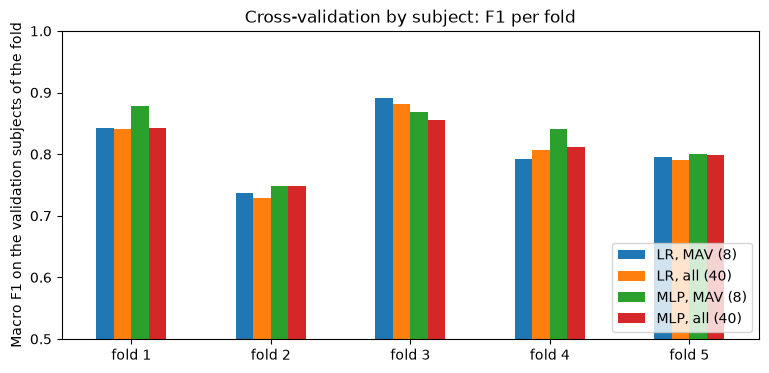

,"LR, MAV (8)","LR, all (40)","MLP, MAV (8)","MLP, all (40)"
fold 1,0.842,0.841,0.878,0.842
fold 2,0.736,0.728,0.749,0.749
fold 3,0.891,0.881,0.868,0.856
fold 4,0.792,0.806,0.841,0.811
fold 5,0.796,0.790,0.800,0.799


In [189]:
# Macro F1 of every fold: is the difference between the models the same in every fold?
f1_per_fold = pd.DataFrame({name: r['test_f1'] for name, r in cv_results.items()},
                           index=['fold %d' % (i + 1) for i in range(5)])

f1_per_fold.plot(kind='bar', figsize=(9,4))
plt.ylim(0.5, 1)
plt.ylabel('Macro F1 on the validation subjects of the fold')
plt.title('Cross-validation by subject: F1 per fold')
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.show()

f1_per_fold.round(3)

Results (5-fold cross-validation by subject, 29 development subjects, macro averages):
- **All scores are lower than on the single validation split** (LR with MAV: F1 0.811 instead of 0.873; MLP: 0.827 instead of 0.888).
  The 7 validation subjects of section 10 were easier than average, and the features were chosen on them in Task 1, so the earlier
  scores were too optimistic. The cross-validation score is based on all 29 people and is a more honest estimate for a new person.
- **The MLP with MAV features is the best model** (F1 0.827 vs 0.811 for logistic regression). It is better in 4 of the 5 folds,
  but the gain (about 1.6 points) is smaller than the spread between folds (standard deviation about 0.05), so the advantage is
  small and not yet certain.
- **All 40 features do not help**, not even for the nonlinear MLP (0.811 vs 0.827 with MAV). The MLP with 40 features fits the
  training subjects almost perfectly (train accuracy 0.999) but does not generalize better. This confirms the Task 1 choice of MAV
  (parsimony): we continue with the **MAV features**.
- **Differences between people are larger than differences between models:** depending on the fold, F1 ranges from about 0.74
  (fold 2) to 0.89 (fold 3) for the same model. Recognizing gestures of a new person is the main difficulty.
- **Overfitting of the MLP:** train accuracy 0.985 against about 0.83 on the validation subjects (logistic regression: 0.863 vs 0.813).
  The MLP has more capacity than it can use for new people (Lecture 6, bias-variance trade-off). In the next step we tune the
  network size, the regularization (`alpha`), the learning rate, the batch size and the number of epochs with the same GroupKFold.

### 14b. Extra check: MAV + WL in cross-validation

In Task 1 (section 12) the forward selection on the 7 validation subjects gave **MAV + WL** a slightly higher F1 than MAV alone
(0.877 vs 0.873). We chose MAV alone because the difference (about 12 windows) was too small to be meaningful, but this was never
checked with the more reliable cross-validation. We do that here.

Choices:
- **Same 5 GroupKFold folds, same models and same settings as above** (logistic regression and the default MLP of section 13),
  so the only difference with the MAV rows of the table above is the feature set.
- **MAV + WL = 16 features** (MAV and waveform length of the 8 channels). MAV and WL are strongly correlated (0.98, section 11), so we
  do not expect much extra information, but WL also reacts to how fast the signal changes, which MAV does not.
- We compare **per fold** as well as on average: because the folds are the same, the difference per fold shows whether one feature set
  is consistently better or only better on average.
- The test subjects are not used.

In [190]:
mav_wl_columns = columns_of(['MAV', 'WL'])

# Same folds and settings as above; only the feature set changes
for name, model in [('LR, MAV + WL (16)', make_lr()), ('MLP, MAV + WL (16)', make_mlp())]:
    cv_results[name] = cross_validate(model, dev[mav_wl_columns], dev['class'], groups=dev['subject'],
                                      cv=group_kfold, scoring=scoring, return_train_score=True)

compare_names = ['LR, MAV (8)', 'LR, MAV + WL (16)', 'MLP, MAV (8)', 'MLP, MAV + WL (16)']
mav_wl_table = pd.DataFrame({name: {'f1': cv_results[name]['test_f1'].mean(),
                                    'f1 std': cv_results[name]['test_f1'].std(),
                                    'accuracy': cv_results[name]['test_accuracy'].mean(),
                                    'train accuracy': cv_results[name]['train_accuracy'].mean()}
                             for name in compare_names}).T
print(mav_wl_table.round(3))
print()

# Difference per fold (MAV + WL minus MAV): positive = MAV + WL is better in that fold
for model in ['LR', 'MLP']:
    difference = cv_results['%s, MAV + WL (16)' % model]['test_f1'] - cv_results['%s, MAV (8)' % model]['test_f1']
    print('%-3s F1 difference per fold (MAV + WL - MAV):' % model, difference.round(3),
          ' better in %d of 5 folds' % (difference > 0).sum())

                       f1  f1 std  accuracy  train accuracy
LR, MAV (8)         0.811   0.052     0.813           0.863
LR, MAV + WL (16)   0.813   0.053     0.814           0.866
MLP, MAV (8)        0.827   0.048     0.828           0.985
MLP, MAV + WL (16)  0.822   0.045     0.823           0.990

LR  F1 difference per fold (MAV + WL - MAV): [ 0.007 -0.002 -0.002  0.004  0.001]  better in 3 of 5 folds
MLP F1 difference per fold (MAV + WL - MAV): [-0.003  0.009  0.005 -0.032 -0.002]  better in 2 of 5 folds


Results (5-fold GroupKFold, 29 development subjects):
- **Logistic regression:** MAV + WL F1 0.813 vs MAV 0.811 (+0.002). Better in 3 of the 5 folds, with per-fold differences between
  -0.002 and +0.007.
- **MLP:** MAV + WL F1 0.822 vs MAV 0.827 (-0.005). Better in only 2 of the 5 folds, and the training accuracy rises from 0.985 to
  0.990: the 8 extra features give the network more room to overfit, without helping for new people.
- All differences (at most 0.005 on average) are **10 times smaller than the spread between the folds** (about 0.05), and they do not
  point in the same direction for the two models. This confirms the small difference seen on the validation subjects in Task 1:
  WL adds practically no information on top of MAV, as expected from their correlation of 0.98 (section 11).
- Decision: we **keep MAV (8 features)** (parsimony: same performance with half the features). The rest of Task 2 is unchanged.

## 15. Hyper-parameter search for the MLP (random search)

The MLP of sections 13-14 used default settings and overfits (train accuracy 0.985 vs about 0.83 on new subjects).
We now search for better settings (hyper-parameters, Lecture 6) with the same 5-fold GroupKFold on the 29 development subjects
and the MAV features (section 14 showed that the 40 features do not help).

Choices:
- **Random search (`RandomizedSearchCV`) instead of grid search:** with 5 hyper-parameters a full grid becomes very large. Random search
  tries random combinations and usually finds equally good settings with far fewer trainings, because only a few hyper-parameters
  really matter (Lecture 6, Quiz 7). We try **30 combinations x 5 folds = 150 trainings**.
- **Hyper-parameters and ranges:**
  - `hidden_layer_sizes`: (32, 16), (64, 32), (128, 64), (64, 32, 16), (128, 64, 32). Always at least 2 hidden layers, so the
    network stays deep; the sizes go from smaller than the default (less overfitting) to larger (more capacity).
  - `alpha` (L2 regularization): between 1e-5 and 1, on a log scale. A larger `alpha` keeps the weights smaller and reduces
    overfitting; this is the most direct way to move along the bias-variance trade-off.
  - `learning_rate_init`: between 1e-4 and 1e-2, on a log scale (step size of the Adam optimizer).
  - `batch_size`: 32, 64, 128, 256 (number of windows per gradient step; small batches give noisier steps).
  - `max_iter` (maximum number of epochs): 25, 50, 100, 200, 400. Because we do not use `early_stopping=True` (section 13), the number
    of epochs is tuned here instead: stopping earlier is another way to prevent overfitting.
  - Log scales are used for `alpha` and the learning rate because their effect depends on the order of magnitude, not on small changes.
- **Score: macro F1**, as before. The best combination is the one with the highest mean F1 over the 5 folds.
- **Train scores are also stored** to see whether the overfitting gap becomes smaller.
- Some combinations stop at `max_iter` before the training loss has converged. scikit-learn then gives a `ConvergenceWarning`; this is
  expected (it is exactly what a small `max_iter` is meant to do), so these warnings are hidden.
- The test subjects are not used.

In [191]:
warnings.filterwarnings('ignore', category=ConvergenceWarning)

param_distributions = {'mlp__hidden_layer_sizes': [(32, 16), (64, 32), (128, 64), (64, 32, 16), (128, 64, 32)],
                       'mlp__alpha': loguniform(1e-5, 1),
                       'mlp__learning_rate_init': loguniform(1e-4, 1e-2),
                       'mlp__batch_size': [32, 64, 128, 256],
                       'mlp__max_iter': [25, 50, 100, 200, 400]}

search = RandomizedSearchCV(make_mlp(), param_distributions, n_iter=30, scoring='f1_macro', cv=group_kfold,
                            return_train_score=True, random_state=42, n_jobs=-1)
search.fit(dev[mav_columns], dev['class'], groups=dev['subject'])

print('Best settings:', search.best_params_)
print('Best mean F1 over the 5 folds: %.3f' % search.best_score_)

Best settings: {'mlp__alpha': np.float64(0.04073745196058384), 'mlp__batch_size': 64, 'mlp__hidden_layer_sizes': (64, 32), 'mlp__learning_rate_init': np.float64(0.0002310201887845295), 'mlp__max_iter': 400}
Best mean F1 over the 5 folds: 0.837


In [192]:
# The 10 best combinations: mean and standard deviation of F1 on the validation folds, and F1 on the training folds
search_results = pd.DataFrame({'hidden layers': search.cv_results_['param_mlp__hidden_layer_sizes'],
                               'alpha': search.cv_results_['param_mlp__alpha'].astype(float),
                               'learning rate': search.cv_results_['param_mlp__learning_rate_init'].astype(float),
                               'batch size': search.cv_results_['param_mlp__batch_size'],
                               'max epochs': search.cv_results_['param_mlp__max_iter'],
                               'val f1': search.cv_results_['mean_test_score'],
                               'val f1 std': search.cv_results_['std_test_score'],
                               'train f1': search.cv_results_['mean_train_score']})
search_results = search_results.sort_values('val f1', ascending=False)
search_results.head(10).round({'alpha': 5, 'learning rate': 5, 'val f1': 3, 'val f1 std': 3, 'train f1': 3})

,hidden layers,alpha,learning rate,batch size,max epochs,val f1,val f1 std,train f1
3,"(64, 32)",0.04074,0.00023,64,400,0.837,0.040,0.968
19,"(128, 64, 32)",0.08931,0.00712,128,50,0.837,0.043,0.950
15,"(128, 64, 32)",0.00088,0.00149,64,25,0.837,0.033,0.968
11,"(64, 32)",0.35205,0.00211,256,50,0.836,0.046,0.944
21,"(128, 64, 32)",0.00003,0.00288,128,100,0.835,0.045,0.985
24,"(128, 64)",0.00001,0.00012,32,25,0.835,0.039,0.934
27,"(64, 32)",0.02978,0.00177,256,25,0.833,0.035,0.946
5,"(64, 32)",0.00421,0.00012,128,200,0.833,0.037,0.951
18,"(128, 64)",0.00029,0.00025,128,100,0.832,0.044,0.960
23,"(128, 64)",0.06367,0.00111,64,50,0.832,0.044,0.960


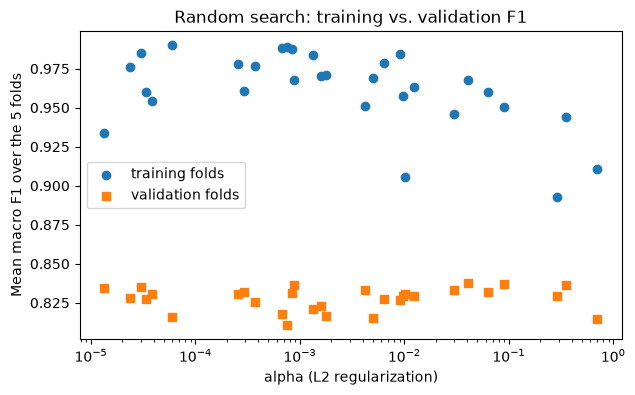

Logistic regression, MAV: F1 0.811 +- 0.052
MLP default settings, MAV: F1 0.827 +- 0.048
MLP tuned settings, MAV:   F1 0.837 +- 0.040  (train F1 0.968)


In [193]:
# Effect of the regularization: F1 on the training and validation folds for every tried combination
plt.figure(figsize=(7,4))
plt.scatter(search_results['alpha'], search_results['train f1'], label='training folds', marker='o')
plt.scatter(search_results['alpha'], search_results['val f1'], label='validation folds', marker='s')
plt.xscale('log')
plt.xlabel('alpha (L2 regularization)')
plt.ylabel('Mean macro F1 over the 5 folds')
plt.title('Random search: training vs. validation F1')
plt.legend()
plt.show()

# Compare the tuned MLP with the models of section 14 (same folds)
best = search_results.iloc[0]
print('Logistic regression, MAV: F1 %.3f +- %.3f' % (cv_table.loc['LR, MAV (8)', 'f1'], cv_table.loc['LR, MAV (8)', 'f1 std']))
print('MLP default settings, MAV: F1 %.3f +- %.3f' % (cv_table.loc['MLP, MAV (8)', 'f1'], cv_table.loc['MLP, MAV (8)', 'f1 std']))
print('MLP tuned settings, MAV:   F1 %.3f +- %.3f  (train F1 %.3f)' % (best['val f1'], best['val f1 std'], best['train f1']))

Results of the random search (5-fold GroupKFold, 29 development subjects, MAV features):
- **Best settings:** hidden layers (64, 32), `alpha` = 0.041, learning rate = 0.00023, batch size 64, at most 400 epochs.
  Mean F1 **0.837 +- 0.040**, against 0.827 +- 0.048 for the default MLP and 0.811 +- 0.052 for logistic regression.
- **Many settings are almost equally good:** the 4 best combinations all score 0.836-0.837 and all 30 combinations lie between 0.811 and
  0.837. The differences between the top combinations are much smaller than the spread between folds (about 0.04), so the exact
  "best" combination is partly luck. The MLP is not very sensitive to its settings, as long as it does not overfit or underfit too much.
- **Bias-variance trade-off (Lecture 6):** most of the weakest combinations fit the training folds almost perfectly (train F1 about
  0.98-0.99) but generalize worse: they overfit. The 4 best combinations have train F1 of about 0.94-0.97: a bit less fit on the
  training subjects, a better fit on new ones. They reach this with stronger L2 regularization (the best one has an `alpha` 400 times
  larger than the default) or with few epochs (25-50). Too much regularization is also bad: the combination with the largest
  `alpha` (0.70) has a low train F1 (0.91) and is among the weakest on the validation folds (underfitting).
- **Gain from tuning:** about +1 point over the default MLP and +2.6 points over logistic regression. The gain over the default MLP is
  smaller than the spread between folds, so tuning helps only a little. Because the best of 30 combinations is selected on the same
  folds, its score of 0.837 is slightly optimistic; the final, unbiased score will come from the test subjects.
- Decision: we continue with the **best settings** found here. The network size (64, 32) is the same as the default, so the network
  stays small and still has 2 hidden layers.

## 16. Learning curves: under- and overfitting during training

The random search gives one score per setting at the end of training. Here we look **inside the training** of the tuned MLP:
after every epoch we measure the loss and the F1 score on the training subjects and on the validation subjects. This shows when the
network stops learning things that also hold for new people (Lecture 6: underfitting vs. overfitting).

Choices:
- **The best settings of section 15** (layers (64, 32), `alpha` = 0.041, learning rate 0.00023, batch size 64), trained for the
  full 400 epochs.
- **One epoch at a time with `partial_fit`.** `MLPClassifier` only stores the training loss (`loss_curve_`), not the validation loss.
  With `partial_fit` we train one epoch, measure both, and continue; the Adam optimizer keeps its state between the calls,
  so this is the same training as `fit`.
- **The same 5 GroupKFold folds as sections 14-15,** and the curves are averaged over the folds. One single split (e.g. the 7 validation
  subjects of section 10) turned out to be easier than average, so the average over 5 folds is more reliable.
- **Loss = cross-entropy (`log_loss`)** on the training and validation subjects, measured in the same way for both. It is the quantity the
  network minimizes, without the L2 penalty, so the two curves can be compared directly. We also show the **macro F1** per epoch.
- The scaler is fitted in every fold on the training subjects of that fold only. The test subjects are not used.

In [194]:


best_mlp_settings = {name.replace('mlp__', ''): value for name, value in search.best_params_.items()}
n_epochs = best_mlp_settings.pop('max_iter')    # partial_fit trains one epoch per call, so max_iter is not used
classes = np.arange(1, 7)

# Loss and F1 after every epoch, for every fold: arrays of shape (number of folds, number of epochs)
curves = {key: np.zeros((5, n_epochs)) for key in ['train loss', 'val loss', 'train f1', 'val f1']}

for fold, (train_idx, val_idx) in enumerate(group_kfold.split(dev, dev['class'], groups=dev['subject'])):
    x_tr, y_tr = dev[mav_columns].iloc[train_idx], dev['class'].iloc[train_idx]
    x_va, y_va = dev[mav_columns].iloc[val_idx], dev['class'].iloc[val_idx]

    scaler = StandardScaler().fit(x_tr)          # fitted on the training subjects of this fold only
    x_tr, x_va = scaler.transform(x_tr), scaler.transform(x_va)

    net = MLPClassifier(**best_mlp_settings, random_state=42)
    for epoch in range(n_epochs):
        net.partial_fit(x_tr, y_tr, classes=classes)
        curves['train loss'][fold, epoch] = log_loss(y_tr, net.predict_proba(x_tr), labels=classes)
        curves['val loss'][fold, epoch] = log_loss(y_va, net.predict_proba(x_va), labels=classes)
        curves['train f1'][fold, epoch] = f1_score(y_tr, net.predict(x_tr), average='macro')
        curves['val f1'][fold, epoch] = f1_score(y_va, net.predict(x_va), average='macro')
    print('Fold %d done' % (fold + 1))

Fold 1 done
Fold 2 done
Fold 3 done
Fold 4 done
Fold 5 done


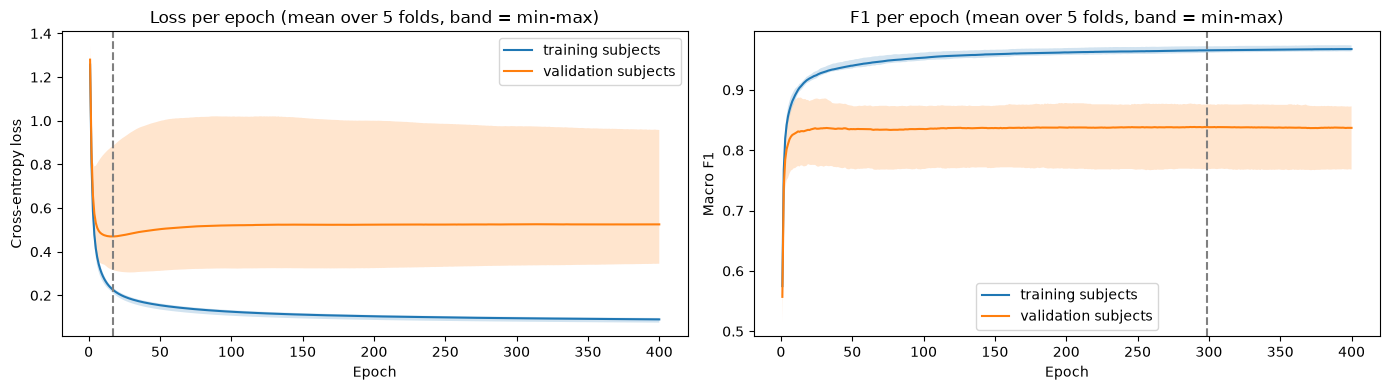

Lowest mean validation loss: 0.470 at epoch 17
Highest mean validation F1:  0.838 at epoch 299
Epoch   1: train loss 1.257  val loss 1.280  train F1 0.575  val F1 0.557
Epoch  10: train loss 0.288  val loss 0.478  train F1 0.891  val F1 0.828
Epoch  25: train loss 0.194  val loss 0.477  train F1 0.924  val F1 0.836
Epoch  50: train loss 0.155  val loss 0.503  train F1 0.940  val F1 0.835
Epoch 100: train loss 0.125  val loss 0.521  train F1 0.953  val F1 0.835
Epoch 200: train loss 0.104  val loss 0.524  train F1 0.962  val F1 0.838
Epoch 300: train loss 0.095  val loss 0.525  train F1 0.966  val F1 0.838
Epoch 400: train loss 0.090  val loss 0.525  train F1 0.968  val F1 0.837


In [195]:
# Average over the 5 folds, with the spread between the folds as a shaded band
epochs = np.arange(1, n_epochs + 1)
mean_curves = {key: values.mean(axis=0) for key, values in curves.items()}
best_epoch_loss = epochs[np.argmin(mean_curves['val loss'])]
best_epoch_f1 = epochs[np.argmax(mean_curves['val f1'])]

fig, axes = plt.subplots(1, 2, figsize=(14,4))
for ax, metric in zip(axes, ['loss', 'f1']):
    for part in ['train', 'val']:
        values = curves['%s %s' % (part, metric)]
        label = 'training subjects' if part == 'train' else 'validation subjects'
        ax.plot(epochs, values.mean(axis=0), label=label)
        ax.fill_between(epochs, values.min(axis=0), values.max(axis=0), alpha=0.2)
    ax.set_xlabel('Epoch')
    ax.legend()
axes[0].axvline(best_epoch_loss, color='gray', linestyle='--')
axes[0].set_ylabel('Cross-entropy loss')
axes[0].set_title('Loss per epoch (mean over 5 folds, band = min-max)')
axes[1].axvline(best_epoch_f1, color='gray', linestyle='--')
axes[1].set_ylabel('Macro F1')
axes[1].set_title('F1 per epoch (mean over 5 folds, band = min-max)')
plt.tight_layout()
plt.show()

print('Lowest mean validation loss: %.3f at epoch %d' % (mean_curves['val loss'].min(), best_epoch_loss))
print('Highest mean validation F1:  %.3f at epoch %d' % (mean_curves['val f1'].max(), best_epoch_f1))
for epoch in [e for e in [1, 10, 25, 50, 100, 200, 300, 400] if e <= n_epochs]:
    print('Epoch %3d: train loss %.3f  val loss %.3f  train F1 %.3f  val F1 %.3f' %
          (epoch, mean_curves['train loss'][epoch - 1], mean_curves['val loss'][epoch - 1],
           mean_curves['train f1'][epoch - 1], mean_curves['val f1'][epoch - 1]))

Results (tuned MLP, MAV features, mean over the 5 GroupKFold folds):
- **Check:** after 400 epochs the mean validation F1 is 0.837, the same as the score of these settings in the random search (section 15),
  so training epoch by epoch with `partial_fit` gives the same result as `fit`.
- **Underfitting at the start:** in the first ~10 epochs the loss is high and the F1 low on both the training and the validation subjects
  (epoch 1: F1 about 0.56). The network has not learned the patterns yet.
- **Best point after about 15-25 epochs:** the validation loss is lowest at epoch 17 (0.470), and the validation F1 reaches about 0.836 at
  epoch 25. After that the network only gets better on the training subjects.
- **Mild overfitting afterwards:** the training loss keeps falling (0.19 at epoch 25 -> 0.09 at epoch 400) and the training F1 keeps rising
  (0.92 -> 0.97), but the validation loss rises a little (0.47 -> 0.52) and the validation F1 stays flat at 0.834-0.839.
  So the extra epochs make the network **more confident** on the training subjects, which makes its probabilities slightly worse for new
  people, but its **predictions (and F1) on new people stay the same**. The validation curves become flat instead of going up, which is
  probably helped by the fairly strong L2 regularization (`alpha` = 0.041; we did not compare this curve without regularization).
- **Differences between people are again larger than the effect of training longer:** after epoch 25 the band between the worst and the
  best fold is about 0.77-0.89 F1, and fold 2 is the hardest at every epoch. The number of epochs changes the mean F1 by at most about 0.005.
- **Conclusion on the number of epochs:** between about 25 and 400 epochs the F1 on new people is practically the same. Fewer epochs
  (about 25) train 16 times faster and give a lower validation loss (better probabilities); 400 epochs is the setting chosen by the random search.

**Decision: the final MLP is trained for 25 epochs instead of 400** (all other settings from section 15 stay the same). Reasons:
- **Same performance on new people:** the validation F1 at epoch 25 (0.836) and at epoch 400 (0.837) differ by 0.001, far less than the
  spread between the folds (about 0.04). The extra 375 epochs do not help for new people.
- **Less overfitting:** at epoch 25 the gap between training and validation F1 is about 0.09 (0.92 vs 0.84), at epoch 400 about 0.13
  (0.97 vs 0.84). The extra epochs only fit the training subjects better (bias-variance trade-off, Lecture 6). With the same validation
  score, the model that fits the training data less tightly is preferred (parsimony).
- **Better probabilities:** the validation loss at epoch 25 (0.48) is close to its minimum (0.47 at epoch 17) and lower than at epoch 400
  (0.52), so the predicted probabilities are more reliable for new people. This matters if the probabilities of several models are
  combined (Task 3).
- **16 times faster training.**
- **Why 25 and not 17** (the epoch with the lowest validation loss): at epoch 17 the F1 is still rising; at epoch 25 it has reached the
  plateau while the loss is still almost minimal. 25 was also one of the values tried in the random search.
- This is **early stopping done on whole subjects**: the stopping point is chosen on validation subjects that were not used for training,
  instead of on a random 10% of windows as `early_stopping=True` would do (section 13).
- Note: 25 epochs was chosen on the same 5 folds, so its score is slightly optimistic; the test subjects will give the unbiased score.

Below we check that a normal `fit` with `max_iter=25` gives the same result in cross-validation.

In [196]:
# Final MLP settings: the best settings of section 15, but trained for 25 epochs
final_mlp_settings = dict(best_mlp_settings, max_iter=25)
print('Final MLP settings:', final_mlp_settings)

def make_final_mlp():
    return Pipeline([('scaler', StandardScaler()), ('mlp', MLPClassifier(**final_mlp_settings, random_state=42))])

# Check with a normal fit on the same 5 folds
cv_final = cross_validate(make_final_mlp(), dev[mav_columns], dev['class'], groups=dev['subject'],
                          cv=group_kfold, scoring=scoring, return_train_score=True)
print('MLP 25 epochs:  val F1 %.3f +- %.3f   train F1 %.3f' % (cv_final['test_f1'].mean(), cv_final['test_f1'].std(),
                                                             cv_final['train_f1'].mean()))
print('MLP 400 epochs: val F1 %.3f +- %.3f   train F1 %.3f' % (best['val f1'], best['val f1 std'], best['train f1']))

Final MLP settings: {'alpha': np.float64(0.04073745196058384), 'batch_size': 64, 'hidden_layer_sizes': (64, 32), 'learning_rate_init': np.float64(0.0002310201887845295), 'max_iter': 25}
MLP 25 epochs:  val F1 0.835 +- 0.037   train F1 0.925
MLP 400 epochs: val F1 0.837 +- 0.040   train F1 0.968


Result of the check: with a normal `fit` and 25 epochs the MLP reaches **F1 0.835 +- 0.037** on the 5 folds, against 0.837 +- 0.040
with 400 epochs: the same score within 0.002, while the training F1 drops from 0.968 to 0.925 (less overfitting).
These **final MLP settings** (layers (64, 32), `alpha` = 0.041, learning rate 0.00023, batch size 64, 25 epochs) are used from here on.

### 16b. Extra check: number of hidden layers (2, 3 or 4)

The project requires at least one **deep** neural network. In the course slides a network counts as deep
with at least 2 (or 3) hidden layers. Our final MLP has 2 hidden layers, which meets the first definition but is on the edge.
Here we check whether a deeper network is just as good, or better, so that the choice of depth is supported by data.

Choices:
- **Architectures** (always a "funnel": every layer is smaller than the one before):
  - 2 hidden layers: (64, 32) - the current final MLP
  - 3 hidden layers: (64, 32, 16) and (128, 64, 32)
  - 4 hidden layers: (64, 32, 16, 8) and (128, 64, 32, 16)
- **All other settings are the final settings of section 16** (`alpha` = 0.041, learning rate 0.00023, batch size 64), so only the depth
  and width change.
- **Two training lengths: 25 and 100 epochs.** A deeper network has more weights and may need more epochs to learn, so comparing all
  depths only at 25 epochs (chosen for the 2-layer network) could be unfair to the deeper ones.
- **Same 5 GroupKFold folds** and the same score (macro F1) as before. Train F1 is also stored to see over- or underfitting.
- The random search of section 15 already tried two 3-layer networks: (128, 64, 32) scored 0.837 (second best of 30) and
  (64, 32, 16) between 0.815 and 0.829. This check compares the depths directly, with the other settings kept equal.
- The test subjects are not used.

In [197]:
architectures = {'2 layers (64, 32)': (64, 32),
                 '3 layers (64, 32, 16)': (64, 32, 16),
                 '3 layers (128, 64, 32)': (128, 64, 32),
                 '4 layers (64, 32, 16, 8)': (64, 32, 16, 8),
                 '4 layers (128, 64, 32, 16)': (128, 64, 32, 16)}

depth_rows = []
for name, layers in architectures.items():
    for epochs in [25, 100]:
        settings = dict(final_mlp_settings, hidden_layer_sizes=layers, max_iter=epochs)
        model = Pipeline([('scaler', StandardScaler()), ('mlp', MLPClassifier(**settings, random_state=42))])
        result = cross_validate(model, dev[mav_columns], dev['class'], groups=dev['subject'], cv=group_kfold,
                                scoring=scoring, return_train_score=True, n_jobs=-1)
        depth_rows.append({'architecture': name, 'epochs': epochs,
                           'val f1': result['test_f1'].mean(), 'val f1 std': result['test_f1'].std(),
                           'train f1': result['train_f1'].mean(), 'fit time (s)': result['fit_time'].mean(),
                           'f1 per fold': result['test_f1'].round(3)})

depth_table = pd.DataFrame(depth_rows).set_index(['architecture', 'epochs'])
depth_table.round(3)

val f1  val f1 std  train f1  fit time (s)  \
architecture               epochs                                               
2 layers (64, 32)          25       0.835       0.037     0.925         1.561   
                           100      0.835       0.040     0.954         5.950   
3 layers (64, 32, 16)      25       0.835       0.046     0.932         1.867   
                           100      0.832       0.054     0.957         6.895   
3 layers (128, 64, 32)     25       0.831       0.043     0.948         2.485   
                           100      0.835       0.040     0.969         9.954   
4 layers (64, 32, 16, 8)   25       0.833       0.048     0.931         1.971   
                           100      0.834       0.043     0.958         7.760   
4 layers (128, 64, 32, 16) 25       0.835       0.046     0.952         2.808   
                           100      0.832       0.054     0.972        11.101   

                                                           f1 per fold  
architecture               epochs                                       
2 layers (64, 32)          25        [0.882, 0.77, 0.85, 0.839, 0.835]  
                           100     [0.878, 0.764, 0.865, 0.832, 0.837]  
3 layers (64, 32, 16)      25      [0.887, 0.752, 0.867, 0.827, 0.841]  
                           100     [0.887, 0.734, 0.879, 0.834, 0.824]  
3 layers (128, 64, 32)     25      [0.875, 0.753, 0.867, 0.828, 0.831]  
                           100     [0.868, 0.763, 0.877, 0.837, 0.828]  
4 layers (64, 32, 16, 8)   25      [0.878, 0.741, 0.868, 0.836, 0.841]  
                           100     [0.876, 0.756, 0.873, 0.827, 0.837]  
4 layers (128, 64, 32, 16) 25       [0.875, 0.751, 0.88, 0.832, 0.836]  
                           100       [0.883, 0.739, 0.886, 0.82, 0.83]

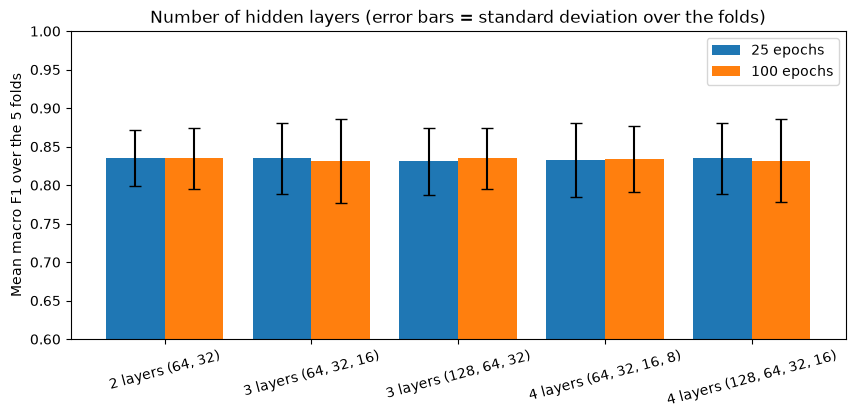

In [198]:
# Validation F1 per architecture and training length, with the spread between the folds as error bars
fig, ax = plt.subplots(figsize=(10,4))
x = np.arange(len(architectures))
for offset, epochs in [(-0.2, 25), (0.2, 100)]:
    rows = depth_table.xs(epochs, level='epochs').loc[list(architectures)]
    ax.bar(x + offset, rows['val f1'], width=0.4, yerr=rows['val f1 std'], capsize=4, label='%d epochs' % epochs)
ax.set_xticks(x)
ax.set_xticklabels(list(architectures), rotation=15)
ax.set_ylim(0.6, 1)
ax.set_ylabel('Mean macro F1 over the 5 folds')
ax.set_title('Number of hidden layers (error bars = standard deviation over the folds)')
ax.legend()
plt.show()

Results (5-fold GroupKFold, 29 development subjects, MAV features):
- **The depth makes no difference for new people:** all 10 combinations score between **0.831 and 0.835** mean F1, while the spread
  between the folds is about 0.04-0.05. The 2-, 3- and 4-layer networks score exactly the same at 25 epochs (0.835 for (64, 32),
  (64, 32, 16) and (128, 64, 32, 16)).
- **Training longer does not help the deeper networks either:** 100 epochs instead of 25 changes the mean F1 by at most 0.004,
  in both directions. It only raises the training F1 (e.g. 0.925 -> 0.954 for 2 layers, 0.952 -> 0.972 for 4 layers), so it adds overfitting.
- **Bigger and deeper networks overfit more:** at 25 epochs the training F1 rises from 0.925 (2 layers, 64-32) to 0.952 (4 layers,
  128-64-32-16), without a better validation F1. The deeper networks also vary a bit more between the folds (std up to 0.054 vs 0.037).
- **Training time** grows with the size of the network (fit times here are measured with several trainings running in parallel, so only
  the ratios matter): the 4-layer (128, 64, 32, 16) network takes about twice as long as the 2-layer network.
- The hardest fold (fold 2) stays the hardest for every architecture (F1 0.73-0.77): the differences between people are again larger
  than the effect of the model.
- Conclusion: with 8 input features there is not enough structure in the data for extra layers to learn anything new.
  3- and 4-layer networks (deep by any definition) were tested and work equally well as the 2-layer network.

**Decision: the final MLP keeps 2 hidden layers (64, 32), 25 epochs.**
- The project requires a deep neural network *as one of the tested models*. The 3- and 4-layer networks above are deep by any
  definition and were tested in the same way as the final model, so this requirement is met.
- With the same score on new people, the smallest network is preferred (parsimony): it overfits least (lowest train F1), varies least
  between the folds (std 0.037) and trains fastest.
- Keeping the final model unchanged also means that sections 17 and 18 stay valid and the **test subjects are not used a second time**.

## 17. Final comparison: logistic regression vs. MLP

Before the test subjects are used, we compare the two final candidates in more detail on the 29 development subjects:
- **Logistic regression** on MAV (the baseline of Task 1, section 14), and
- **the final MLP** on MAV (settings of section 15, 25 epochs, section 16).

Choices:
- **Out-of-fold predictions (`cross_val_predict`) with the same 5 GroupKFold folds:** every window is predicted by a model that was trained
  without that window's subject. This gives one prediction for every window of all 29 subjects, so we can make a confusion matrix and a
  score **per subject** for all 29 people, instead of only for the 7 validation subjects of section 13.
- **F1 per subject:** section 14 showed that the differences between people are larger than the differences between models. Comparing the
  two models subject by subject shows whether the MLP is better for most people or only on average.
- **Training time** (`fit_time` of the cross-validation) is also compared, as a practical argument next to the scores.
- The final model is chosen **here**, before the test subjects are used, so the test score in section 18 is not used to choose anything.

In [199]:

# Out-of-fold predictions: every window is predicted by the model of the fold in which its subject was left out
oof_pred = {'Logistic regression': cross_val_predict(make_lr(), dev[mav_columns], dev['class'],
                                                     groups=dev['subject'], cv=group_kfold),
            'MLP (final)': cross_val_predict(make_final_mlp(), dev[mav_columns], dev['class'],
                                             groups=dev['subject'], cv=group_kfold)}

# Summary of all models of Task 2 (mean over the 5 folds) and the mean training time per fold
summary = pd.DataFrame({'f1': [cv_table.loc['LR, MAV (8)', 'f1'], cv_table.loc['LR, all (40)', 'f1'],
                               cv_table.loc['MLP, MAV (8)', 'f1'], cv_table.loc['MLP, all (40)', 'f1'],
                               best['val f1'], cv_final['test_f1'].mean()],
                        'f1 std': [cv_table.loc['LR, MAV (8)', 'f1 std'], cv_table.loc['LR, all (40)', 'f1 std'],
                                   cv_table.loc['MLP, MAV (8)', 'f1 std'], cv_table.loc['MLP, all (40)', 'f1 std'],
                                   best['val f1 std'], cv_final['test_f1'].std()]},
                       index=['LR, MAV', 'LR, all 40', 'MLP default, MAV', 'MLP default, all 40',
                              'MLP tuned 400 epochs, MAV', 'MLP final (25 epochs), MAV'])
print(summary.round(3))
print()
print('F1 per fold, logistic regression:', cv_results['LR, MAV (8)']['test_f1'].round(3))
print('F1 per fold, final MLP:          ', cv_final['test_f1'].round(3))
print()
print('Mean training time per fold: logistic regression %.2f s, final MLP %.2f s'
      % (cv_results['LR, MAV (8)']['fit_time'].mean(), cv_final['fit_time'].mean()))

                               f1  f1 std
LR, MAV                     0.811   0.052
LR, all 40                  0.809   0.051
MLP default, MAV            0.827   0.048
MLP default, all 40         0.811   0.037
MLP tuned 400 epochs, MAV   0.837   0.040
MLP final (25 epochs), MAV  0.835   0.037

F1 per fold, logistic regression: [0.842 0.736 0.891 0.792 0.796]
F1 per fold, final MLP:           [0.882 0.77  0.85  0.839 0.835]

Mean training time per fold: logistic regression 0.18 s, final MLP 1.27 s


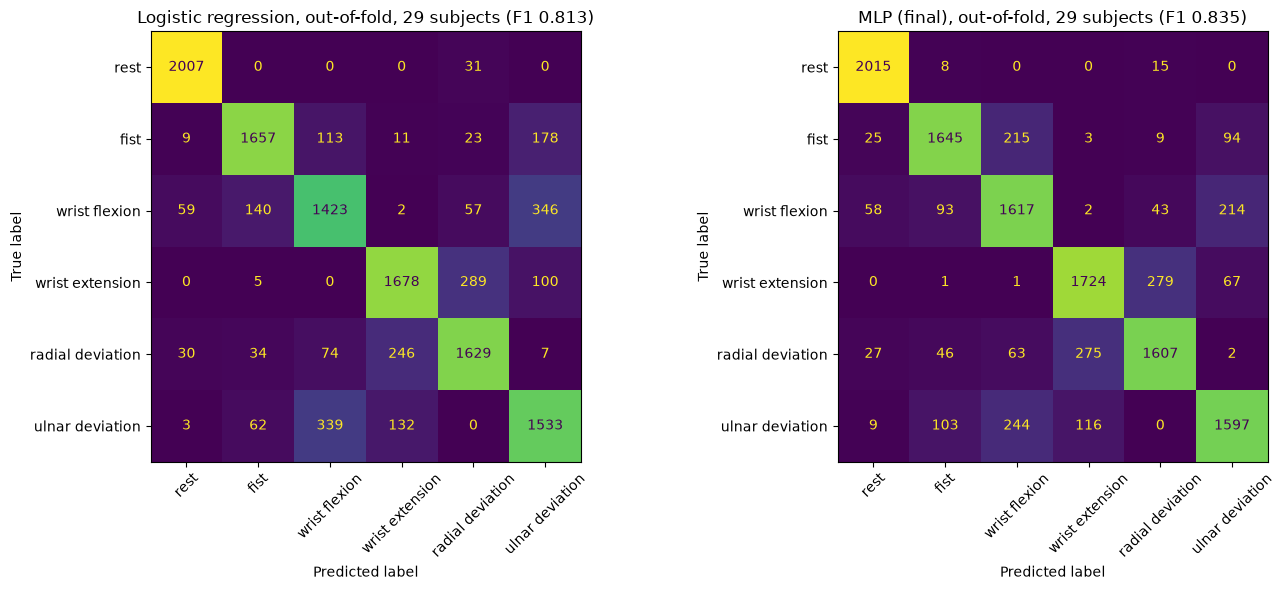

,Logistic regression,MLP (final)
rest,0.985,0.989
fist,0.832,0.826
wrist flexion,0.702,0.798
wrist extension,0.810,0.832
radial deviation,0.806,0.796
ulnar deviation,0.741,0.772


In [200]:
# Confusion matrices of the out-of-fold predictions (all 29 development subjects)
fig, axes = plt.subplots(1, 2, figsize=(14,6))
for ax, (name, y_pred) in zip(axes, oof_pred.items()):
    disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(dev['class'], y_pred),
                                  display_labels=[class_names[c] for c in range(1, 7)])
    disp.plot(ax=ax, xticks_rotation=45, colorbar=False)
    ax.set_title('%s, out-of-fold, 29 subjects (F1 %.3f)' % (name, f1_score(dev['class'], y_pred, average='macro')))
plt.tight_layout()
plt.show()

# Recall per class: which gestures are recognized best and worst?
recall_per_class = pd.DataFrame({name: recall_score(dev['class'], y_pred, average=None) for name, y_pred in oof_pred.items()},
                                index=[class_names[c] for c in range(1, 7)])
recall_per_class.round(3)

MLP better for 19 of 29 subjects, worse for 10
Median difference (MLP - LR): 0.035
Lowest subject F1:  LR 0.331, MLP 0.377
Highest subject F1: LR 0.994, MLP 0.987


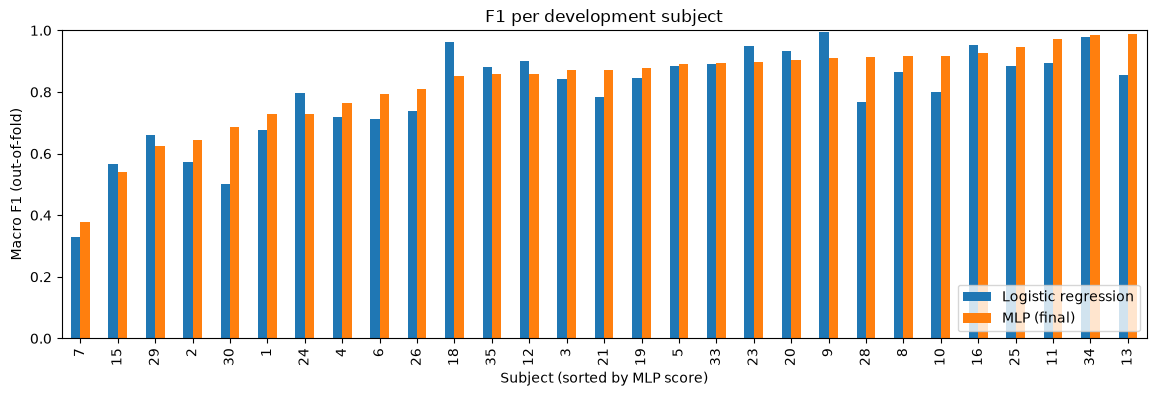

In [201]:
# Macro F1 per subject (out-of-fold), for both models
subject_f1 = pd.DataFrame({name: [f1_score(dev['class'][dev['subject'] == s], y_pred[(dev['subject'] == s).values], average='macro')
                                  for s in np.sort(dev['subject'].unique())]
                           for name, y_pred in oof_pred.items()},
                          index=np.sort(dev['subject'].unique()))
subject_f1.index.name = 'subject'
subject_f1['difference'] = subject_f1['MLP (final)'] - subject_f1['Logistic regression']

print('MLP better for %d of %d subjects, worse for %d' % ((subject_f1['difference'] > 0).sum(), len(subject_f1),
                                                         (subject_f1['difference'] < 0).sum()))
print('Median difference (MLP - LR): %.3f' % subject_f1['difference'].median())
print('Lowest subject F1:  LR %.3f, MLP %.3f' % (subject_f1['Logistic regression'].min(), subject_f1['MLP (final)'].min()))
print('Highest subject F1: LR %.3f, MLP %.3f' % (subject_f1['Logistic regression'].max(), subject_f1['MLP (final)'].max()))

# Subjects sorted from hardest to easiest (by the MLP score)
order = subject_f1.sort_values('MLP (final)').index
subject_f1.loc[order, ['Logistic regression', 'MLP (final)']].plot(kind='bar', figsize=(14,4))
plt.ylim(0, 1)
plt.xlabel('Subject (sorted by MLP score)')
plt.ylabel('Macro F1 (out-of-fold)')
plt.title('F1 per development subject')
plt.legend(loc='lower right')
plt.show()

Results (29 development subjects, out-of-fold predictions):
- **Scores:** the final MLP reaches F1 **0.835** (mean over the folds, +- 0.037), logistic regression **0.811** (+- 0.052).
  Computed over all out-of-fold predictions together, the F1 scores are almost the same (0.835 and 0.813).
  Per fold, the final MLP is better than logistic regression in 4 of the 5 folds (all except fold 3).
- **Confusion matrices:** both models recognize **rest** almost perfectly (recall 0.99). The two main confusions are the same for both
  models: **wrist flexion <-> ulnar deviation** and **wrist extension <-> radial deviation** (these gestures use partly the same muscles).
  The MLP reduces the first confusion clearly (flexion predicted as ulnar deviation: 346 -> 214 windows; the other way: 339 -> 244), which
  raises the recall of wrist flexion from 0.70 to 0.80. Extension <-> radial deviation does not improve (about 280 windows in both
  directions for both models). The MLP confuses fist with wrist flexion more often (113 -> 215 windows).
- **Per subject:** the MLP is better for **19 of the 29 subjects** and worse for 10 (median difference +0.035). For some subjects the gain is
  large (e.g. subject 30: 0.50 -> 0.69, subject 13: 0.85 -> 0.99), but for a few the MLP is clearly worse (subject 18: 0.96 -> 0.85).
- **The differences between people are much larger than between the models:** with the MLP the F1 per subject ranges from **0.38**
  (subject 7) to **0.99**, and 5 subjects score below 0.7. Subject 7 is hard for both models (LR 0.33). A model trained on other people does
  not work equally well for everyone, probably because of differences in arm anatomy and in the position of the bracelet. This is the main
  limitation of the approach, not the choice of classifier.
- **Training time:** 0.09 s per fold for logistic regression and 1.0 s for the MLP (about 10,000 windows). Both are very fast. The
  prediction time was not measured separately, but for such small models it is negligible compared with the 190 ms window length.

**Choice of the final model: the MLP (25 epochs, MAV features).**
- It has the highest cross-validated F1 (0.835 vs 0.811), is better in 4 of the 5 folds and for 19 of the 29 subjects,
  and it reduces the largest confusion of the linear model.
- **Trade-off (Lecture 6):** logistic regression is simpler and easier to interpret (one weight per channel and class, which can be read as
  "which muscle activity points to which gesture"), while the MLP is a black box. The gain of the MLP (about 2.4 points) is modest, but it is
  mostly consistent over folds and subjects, and the MLP is still small (8 inputs, 2 hidden layers of 64 and 32 neurons) and fast. We therefore
  accept the loss of interpretability for the better accuracy. The project also requires a deep neural network.
- **Logistic regression is kept as the baseline:** in section 18 both models are trained on all 29 development subjects and scored once
  on the test subjects. The choice above is made now and is **not** changed based on the test scores.

## 18. Final evaluation on the test subjects

The final model (MLP, 25 epochs, MAV features) was chosen in section 17. Now, for the first and only time, the **7 test subjects**
(set aside in section 10) are used.

Choices:
- **Train on all 29 development subjects:** cross-validation was only needed to choose the model and its settings. For the final model we
  use all available development data, because more people in the training set should help it work for new people.
- **Score once on the 7 test subjects** with the same metrics as before (accuracy, precision, recall, macro F1), plus a confusion matrix
  and the F1 per test subject. These subjects were not used for any choice (features, window length, model, hyper-parameters, number of
  epochs), so this is an unbiased estimate of how well the model works for a new person.
- **Logistic regression (MAV) is scored as well, as a reference.** It does not change the choice of section 17: the MLP stays the final model
  whatever the test scores are.
- The test score is compared with the cross-validation estimate (F1 0.835 +- 0.037) to see whether the estimate was realistic.

In [202]:
# Train both models on all 29 development subjects
final_model = make_final_mlp().fit(dev[mav_columns], dev['class'])
baseline_model = make_lr().fit(dev[mav_columns], dev['class'])

# First and only use of the test subjects
test_pred = {'MLP (final)': final_model.predict(test[mav_columns]),
             'Logistic regression (baseline)': baseline_model.predict(test[mav_columns])}

test_scores = pd.DataFrame({name: scores_of(test['class'], y_pred) for name, y_pred in test_pred.items()}).T
print('Test subjects:', np.sort(test_subjects), ' windows:', len(test))
test_scores.round(3)

Test subjects: [14 17 22 27 31 32 36]  windows: 2852


,accuracy,precision,recall,f1
MLP (final),0.781,0.786,0.779,0.780
Logistic regression (baseline),0.802,0.812,0.801,0.802


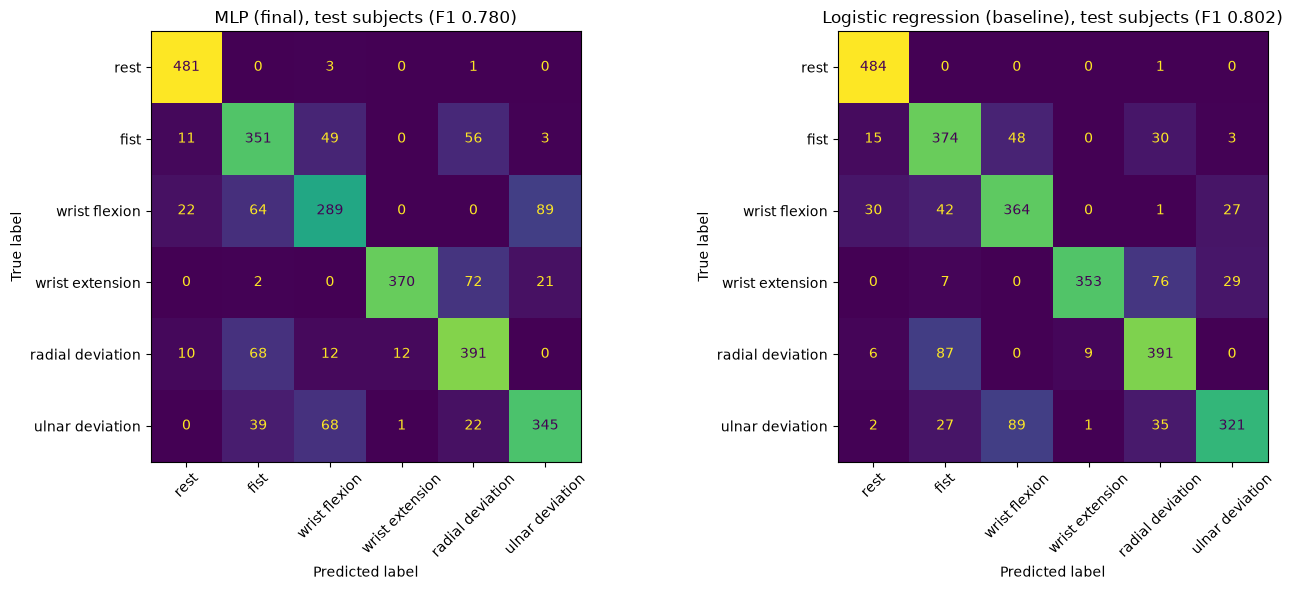

Final MLP: cross-validation F1 0.835 +- 0.037, test F1 0.780


,MLP (final),Logistic regression (baseline)
subject,,
14,0.577,0.696
17,0.901,0.813
22,0.246,0.296
27,0.840,0.951
31,0.797,0.822
32,0.996,0.998
36,0.866,0.824


In [203]:
# Confusion matrices on the test subjects
fig, axes = plt.subplots(1, 2, figsize=(14,6))
for ax, (name, y_pred) in zip(axes, test_pred.items()):
    disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(test['class'], y_pred),
                                  display_labels=[class_names[c] for c in range(1, 7)])
    disp.plot(ax=ax, xticks_rotation=45, colorbar=False)
    ax.set_title('%s, test subjects (F1 %.3f)' % (name, f1_score(test['class'], y_pred, average='macro')))
plt.tight_layout()
plt.show()

# Macro F1 per test subject
test_subject_f1 = pd.DataFrame({name: [f1_score(test['class'][test['subject'] == s], y_pred[(test['subject'] == s).values],
                                                average='macro') for s in np.sort(test_subjects)]
                                for name, y_pred in test_pred.items()},
                               index=np.sort(test_subjects))
test_subject_f1.index.name = 'subject'

# Comparison with the cross-validation estimate of section 17
print('Final MLP: cross-validation F1 %.3f +- %.3f, test F1 %.3f' % (cv_final['test_f1'].mean(), cv_final['test_f1'].std(),
                                                                   test_scores.loc['MLP (final)', 'f1']))
test_subject_f1.round(3)

In [204]:
# How much does the MLP test score depend on the random initial weights? (analysis only, the final model is not changed)
seed_f1 = []
for seed in range(5):
    model = Pipeline([('scaler', StandardScaler()), ('mlp', MLPClassifier(**final_mlp_settings, random_state=seed))])
    model.fit(dev[mav_columns], dev['class'])
    seed_f1.append(f1_score(test['class'], model.predict(test[mav_columns]), average='macro'))
print('MLP test F1 with random_state 0-4:', np.round(seed_f1, 3))
print('Logistic regression test F1:      %.3f' % test_scores.loc['Logistic regression (baseline)', 'f1'])

MLP test F1 with random_state 0-4: [0.796 0.785 0.788 0.785 0.794]
Logistic regression test F1:      0.802


Results on the 7 test subjects (2852 windows, macro averages):
- **Final MLP: F1 0.780** (accuracy 0.781). **Logistic regression: F1 0.802** (accuracy 0.802).
- **The test score of the MLP is lower than the cross-validation estimate** (0.835 +- 0.037). It lies about 1.5 standard deviations below
  the mean of the folds, so it is at the low end of what the folds showed, but not impossible: with only 7 people, one very difficult
  person changes the result a lot. **Subject 22** is recognized very badly by both models (MLP 0.25, LR 0.30), similar to subject 7 in the
  development set. The average F1 of the other 6 test subjects is about 0.83 for the MLP and 0.85 for logistic regression.
- **On the test subjects, logistic regression is better than the MLP** (by about 2 points), the opposite of the cross-validation result.
  The MLP is better for 2 of the 7 test subjects (17 and 36) and worse for 5. This is **not caused by an unlucky random initialization**:
  with 5 other random seeds the MLP scores 0.785-0.796 on the test subjects, always below logistic regression (0.802).
- **Confusion matrix:** the same gesture pairs are confused as before (wrist flexion <-> ulnar deviation, wrist extension <-> radial deviation,
  and fist <-> wrist flexion / radial deviation). Unlike in cross-validation, the MLP is now **worse** for wrist flexion (recall 0.62 vs 0.78),
  mainly because it predicts ulnar deviation more often (89 vs 27 windows).

Interpretation:
- The advantage of the MLP in cross-validation was small (2.4 points, smaller than the spread between folds of about 0.04), and it was found
  after choosing the best of 30 hyper-parameter combinations and the number of epochs on the same folds, which makes it slightly optimistic.
  Logistic regression had no settings tuned in Task 2. On 7 new people the small advantage did not hold.
- The honest conclusion is that **both models perform about equally well for new people** (F1 about 0.78-0.80 on the test subjects,
  0.81-0.84 in cross-validation). **The differences between people are much larger than the differences between the models**
  (test F1 per subject from 0.25 to 1.00), which agrees with sections 14-17.
- As decided in section 17, **the MLP remains our final model**; the test result is reported as it is and is not used to change the choice
  (changing the model now would make the test score optimistic as well). For a final product, the simpler and more interpretable logistic
  regression would be an equally good choice (parsimony).
- The largest possible improvement is not a different classifier but **dealing with the differences between people**, for example a short
  calibration recording of each new user, or combining several diverse models (Task 3).

## Summary of Task 2

| Step | Section | Choice | Result (macro F1) |
|---|---|---|---|
| First MLP | 13 | `StandardScaler` + `MLPClassifier` (2 hidden layers, 64-32), no `early_stopping=True` (would mix windows of one subject) | 0.888 vs LR 0.873 on the 7 validation subjects |
| Validation | 14 | 5-fold `GroupKFold` by subject on the 29 development subjects; test subjects locked away | LR 0.811, MLP 0.827; all 40 features do not help, so MAV is kept |
| Hyper-parameters | 15 | `RandomizedSearchCV`, 30 combinations of layers, `alpha`, learning rate, batch size and epochs | best 0.837 +- 0.040; stronger regularization reduces overfitting |
| Learning curves | 16 | Train vs. validation loss per epoch (`partial_fit`), averaged over the folds | best point at about 17-25 epochs; final MLP uses 25 epochs: 0.835 +- 0.037 |
| Comparison | 17 | Out-of-fold predictions for all 29 subjects; final model chosen before testing | MLP better for 19 of 29 subjects; F1 per subject 0.38-0.99 |
| Final test | 18 | Trained on all 29 development subjects, scored once on the 7 test subjects | **MLP 0.780**, LR 0.802 |

Conclusion: a small deep neural network (MLP) and logistic regression on the MAV features both recognize the 6 gestures of a new person
with an F1 of about 0.78-0.84. The MLP was slightly better in cross-validation but slightly worse on the test subjects, so neither model
is clearly better. The main limitation is the large difference between people (F1 per subject from about 0.25 to 1.00), not the classifier.

## Comments / questions / thoughts

* We have only tried an MLP, and tuned that, maybe we try more neural networks and tune thos as well. 
* Maybe we make the MLP with more layers, just to see. The pdf says to use at least on deep nn. And one lecture says that a deep nn is ">=2 (or 3)", so maybe we do 3 or 4 to garuantee we hit this
*  MAV + WL was never tested in cross-validation
* **From professor:** He does not care so much about the accuracy, more so a about the pipeline. This should be documented well and well thought out